# Film-thickness crop of reconstructed magnetization volume
Loads a `.vti`/`.vtr` reconstruction, crops the z-stack to the true material thickness (symmetric around a known center voxel), and plots the center-y slice (Mz contrast) before/after to verify the crop landed on the right region.

In [1]:
# --- Cell: imports ---
import os
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import sys
sys.path.append('.')  # folder containing vti_magnetic_import.py
from vti_magnetic_import import load_vti_sample, inspect_vti
import Functions_3D as vis

from scipy.ndimage import gaussian_filter, map_coordinates

import matplotlib.ticker as mticker



## 1. Per-sample film thickness lookup
Same pattern as your existing config -- extended into a small function so it can be called for any sample name.

In [3]:
def get_sample_cfg(sample):
    """Return {'center1': <z voxel index>, 'film_thickness_nm': <float>} for a sample name."""
    cfg = {}
    if sample in ('665', '665_magconst'):

        cfg['film_thickness_nm'] = 51
    elif sample in ('270', '270_magconst'):

        cfg['film_thickness_nm'] = 66
    elif sample in ('452', '452_magconst', '452_orig'):

        cfg['film_thickness_nm'] = 33
    elif sample in ('105', '105_magconst', '105_orig'):

        cfg['film_thickness_nm'] = 45
    elif sample == 'test_sample_tall':
        # demo-only entry for the synthetic sanity-check volume below --
        # remove once you're pointing this at real data

        cfg['film_thickness_nm'] = 40
    else:
        raise KeyError(f"No crop config defined for sample '{sample}' -- add an entry above.")
    return cfg


## 2. Load the volume
Split into separate config / inspect / load cells so you can edit the path and re-run just that cell, without reloading everything else. The loader auto-detects file format (XML `.vti`/`.vtr`, or legacy `.vtk` in ASCII or binary) from the file content, and auto-detects the vector array name unless you specify one.

In [5]:
sample_name = '452'

# data_dir = r'C:\Users\emmab\Projects\Vector_Tomography\data_dir'
#data_dir = r'C:\Users\emmab\Box\KukrejaLab\Projects\3D Imaging_Emma\Analysis\data_dir'
data_dir = r"C:\Users\emmab\Projects\Vector_Tomography\data_dir\452_orig"
# test_filename = f"{sample_name}_cropped_magconst_14AUG26_ascii.vtk"
# test_filename = f"{sample_name}_cropped_magconst_22AUG26_ascii.vtk"
test_filename = f"{sample_name}_cropped_original.vtk"
test_path = os.path.join(data_dir, test_filename)
inspect_vti(test_path)

File: C:\Users\emmab\Projects\Vector_Tomography\data_dir\452_orig\452_cropped_original.vtk  (kind: rectilinear)
  Dimensions (nx, ny, nz): (101, 101, 15)
  X coords: [0, 100], uniform spacing
  Y coords: [0, 100], uniform spacing
  Z coords: [0, 14], uniform spacing
  Point data (1 arrays):
    - 'M': 3 component(s), 153015 tuples, dtype=double
  Cell data (0 arrays):


<vtkmodules.vtkCommonDataModel.vtkRectilinearGrid(0x000002F9861A6B10) at 0x000002F9AB4EDD80>

In [7]:
# --- Cell: load the sample and summarize ---
samples = {}
samples[sample_name] = load_vti_sample(test_path, sample_name=sample_name)

s = samples[sample_name]
print("\nLoaded sample summary:")
for k, v in s.items():
    if isinstance(v, np.ndarray):
        print(f"  {k}: shape={v.shape}, dtype={v.dtype}")
    else:
        print(f"  {k}: {v}")

print("\nmagnitude min/max:", s["magnitude"].min(), s["magnitude"].max())


[load_vti_sample] No vector_array given — auto-selected 'M'

Loaded sample summary:
  name: 452
  path: C:\Users\emmab\Projects\Vector_Tomography\data_dir\452_orig\452_cropped_original.vtk
  kind: rectilinear
  dims: (101, 101, 15)
  x_coords: shape=(101,), dtype=float64
  y_coords: shape=(101,), dtype=float64
  z_coords: shape=(15,), dtype=float64
  shape: (15, 101, 101)
  X: shape=(15, 101, 101), dtype=float64
  Y: shape=(15, 101, 101), dtype=float64
  Z: shape=(15, 101, 101), dtype=float64
  Mx: shape=(15, 101, 101), dtype=float64
  My: shape=(15, 101, 101), dtype=float64
  Mz: shape=(15, 101, 101), dtype=float64
  M_vec: shape=(15, 101, 101, 3), dtype=float64
  magnitude: shape=(15, 101, 101), dtype=float64
  mask: shape=(15, 101, 101), dtype=bool

magnitude min/max: 1.4842505244719336e-05 0.005090514552105415


# Crop Volume and verify slice
Crops every `(nz, ny, nx)` / `(nz, ny, nx, 3)` array in the sample dict to `film_thickness_nm`, symmetric around len(z-voxel)/2. Returns a new dict -- the original volume is left untouched.

In [8]:
cfg = get_sample_cfg(sample_name)
# samples[sample_name]['cropped'] = vis.crop_volume_by_thickness(
#     samples[sample_name],
#     film_thickness_nm=cfg['film_thickness_nm'],
# )


samples[sample_name]['cropped'] = vis.crop_interpolate_volume_by_thickness(
    samples[sample_name],
    film_thickness_nm=cfg['film_thickness_nm'],
)

Original shape: (15, 101, 101), voxel size: 8.0 nm
Interpolating to 2.0 nm voxels (scale x4)...
Interpolated shape: (60, 404, 404)
z-center: 7.118644067796611
[452] z crop (at 2.0 nm/vox): [22:38) -> actual thickness = 32.00 nm (target 33 nm)
    total voxels: 9792960 (interpolated, full) -> 2611456 (cropped), 26.7% retained


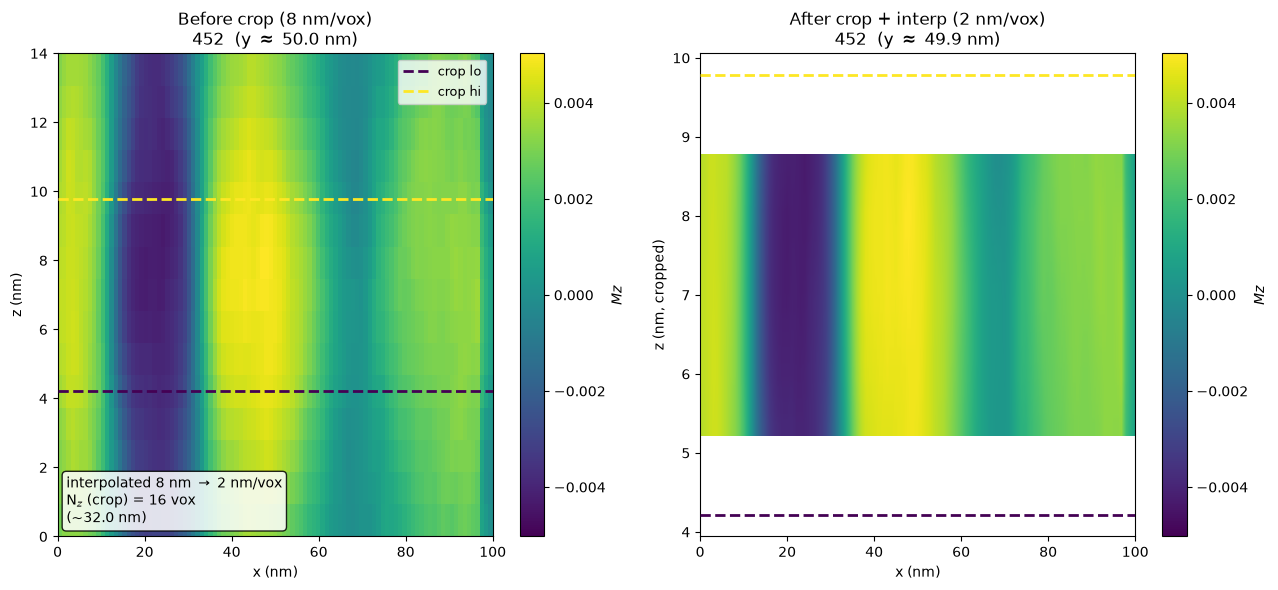

Voxel size: 8 nm -> interpolated to 2 nm
Shape: (15, 101, 101) (full, 8 nm/vox) -> (16, 404, 404) (cropped, 2 nm/vox)
Total voxels: 153015 (full) -> 2611456 (cropped)
z-thickness kept: 32.00 nm (target 33.00 nm)


In [9]:
nz, ny, nx = samples[sample_name]['shape']
vis.plot_crop_interpolation_verification(samples[sample_name], samples[sample_name]['cropped'], field='Mz')

# Visualize Fancy

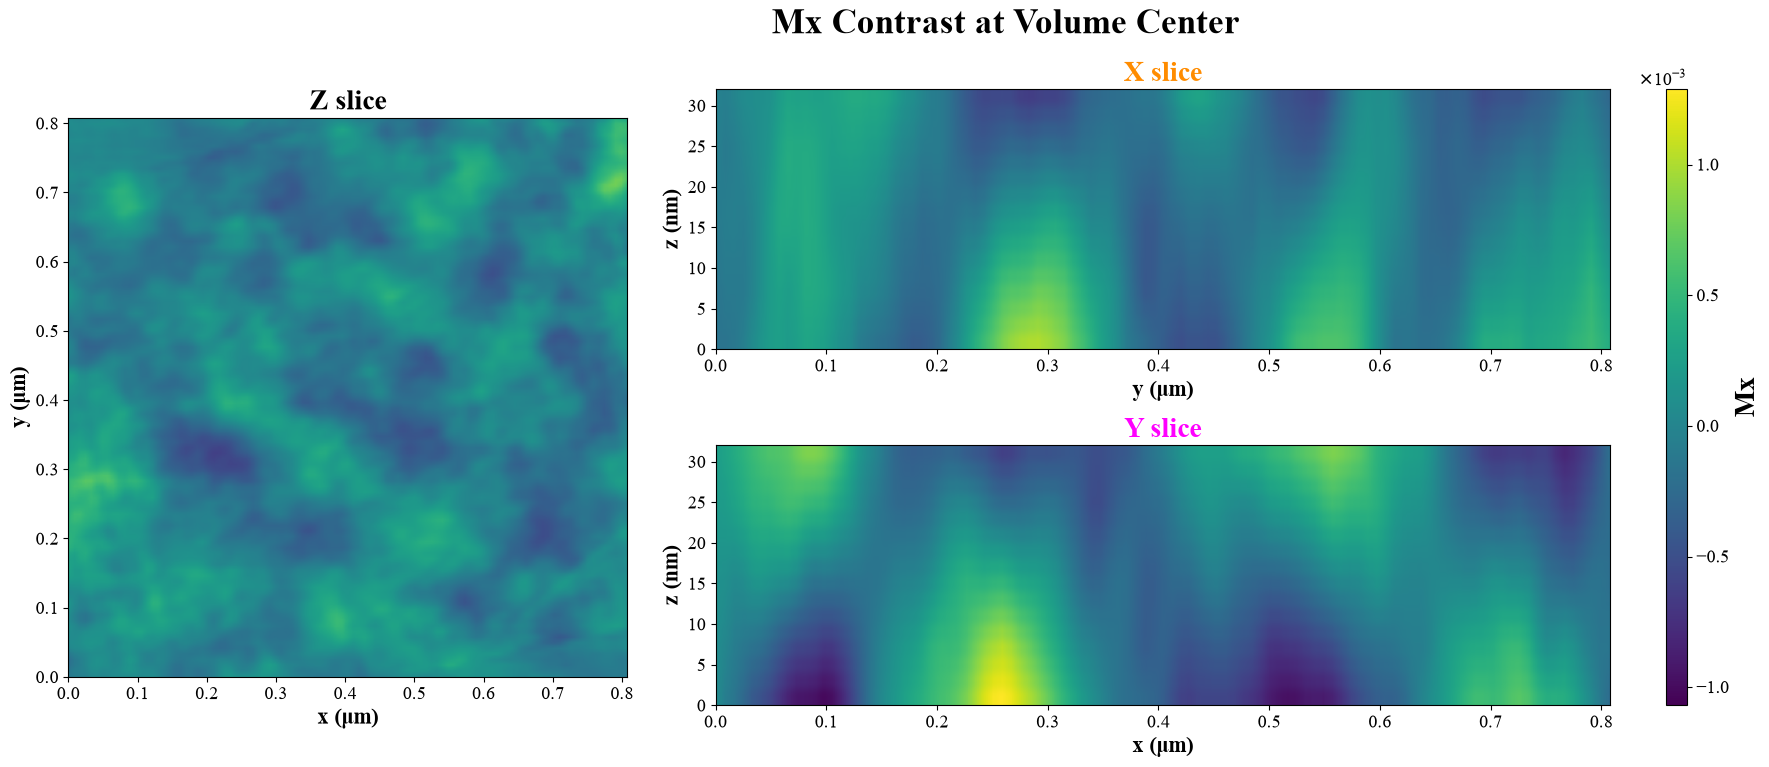

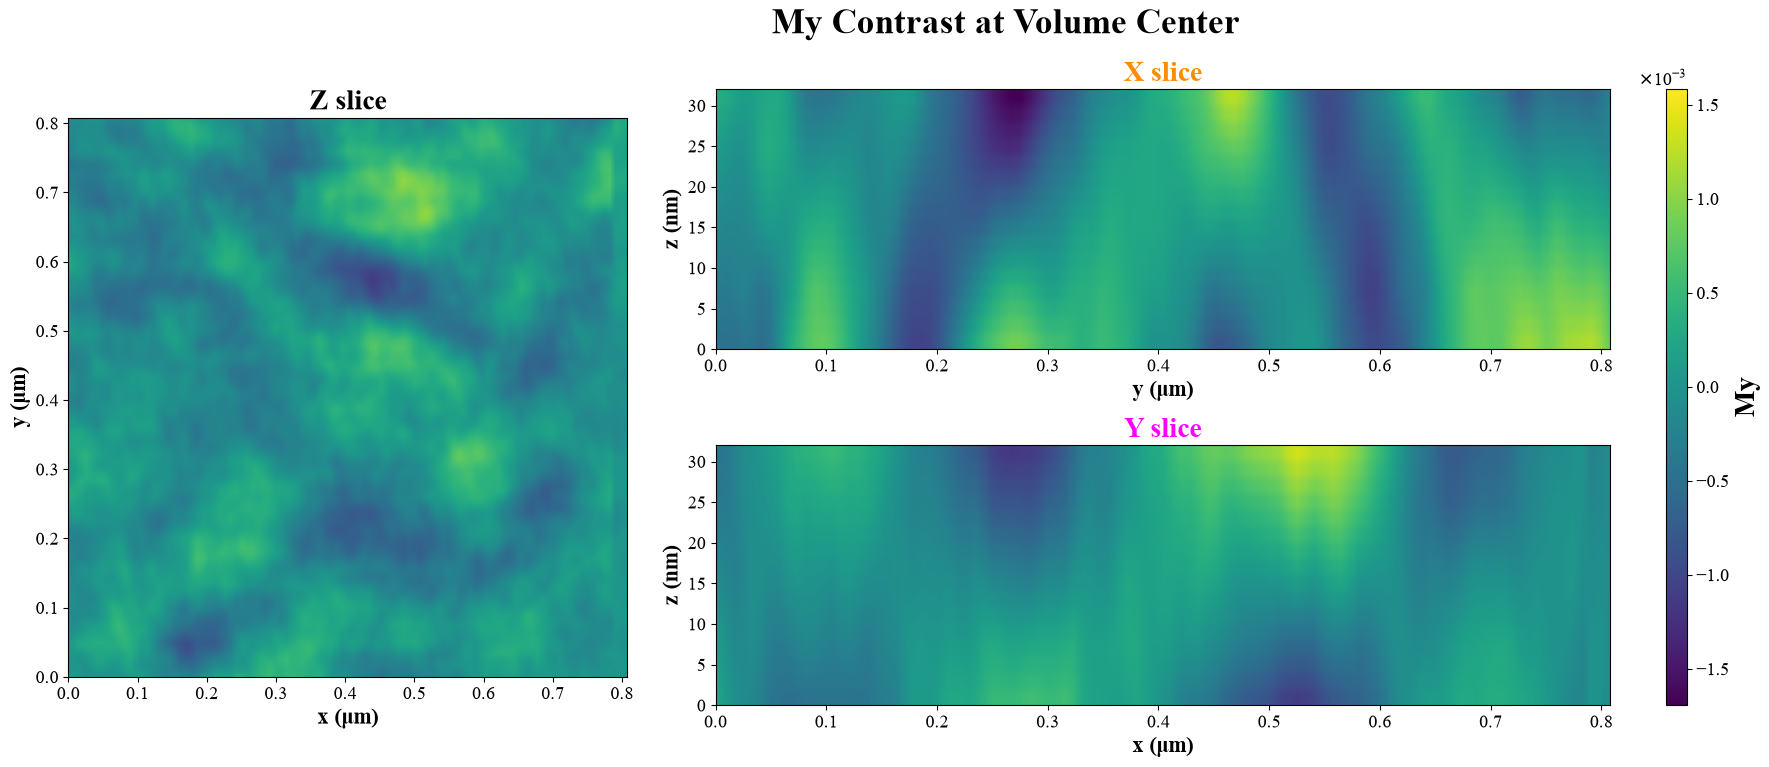

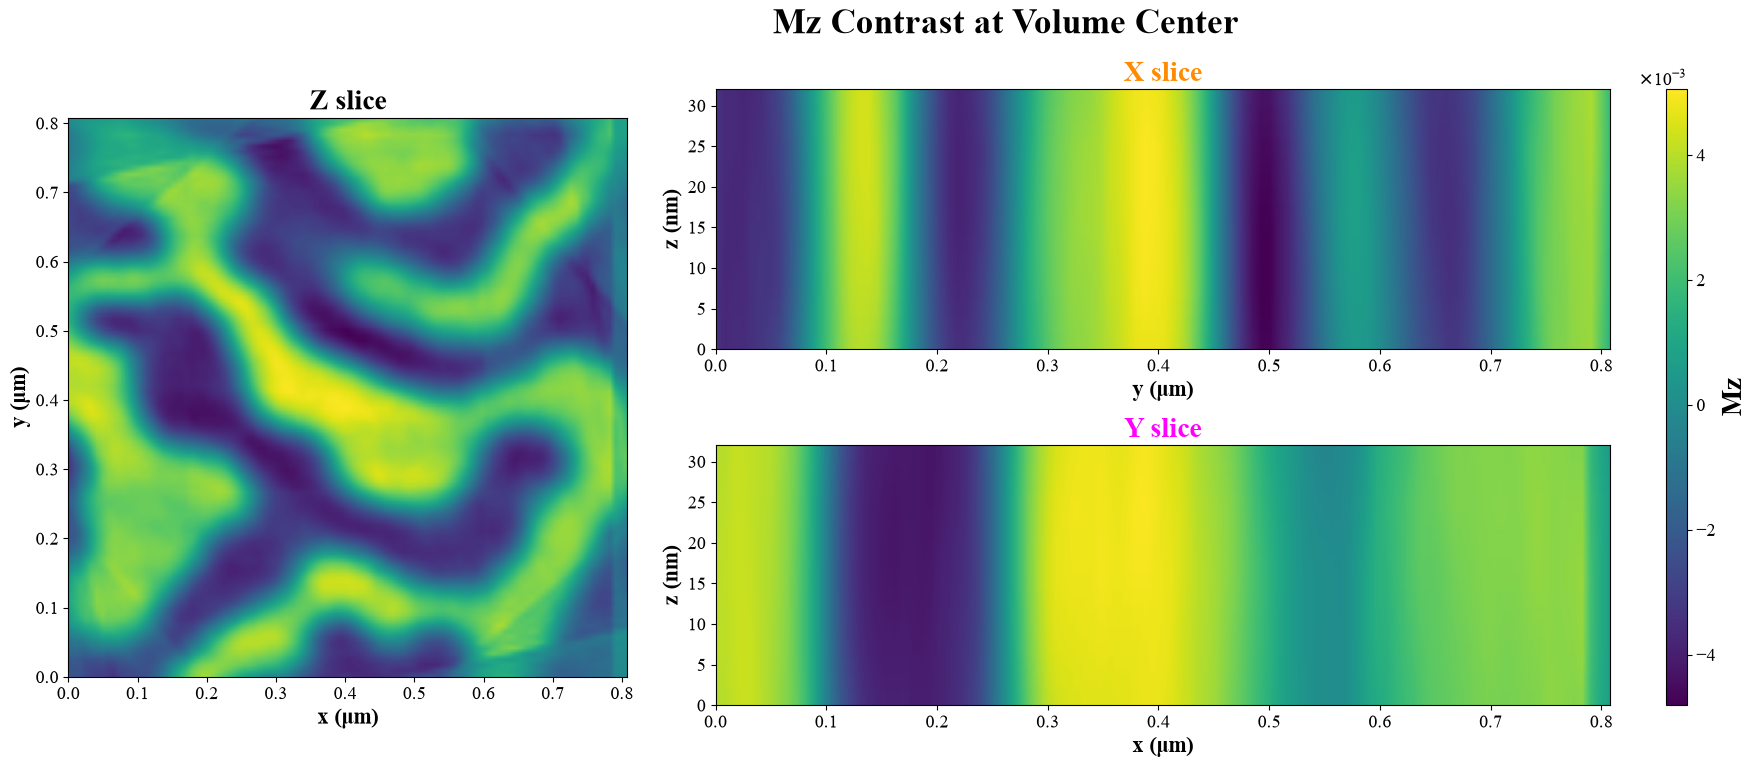

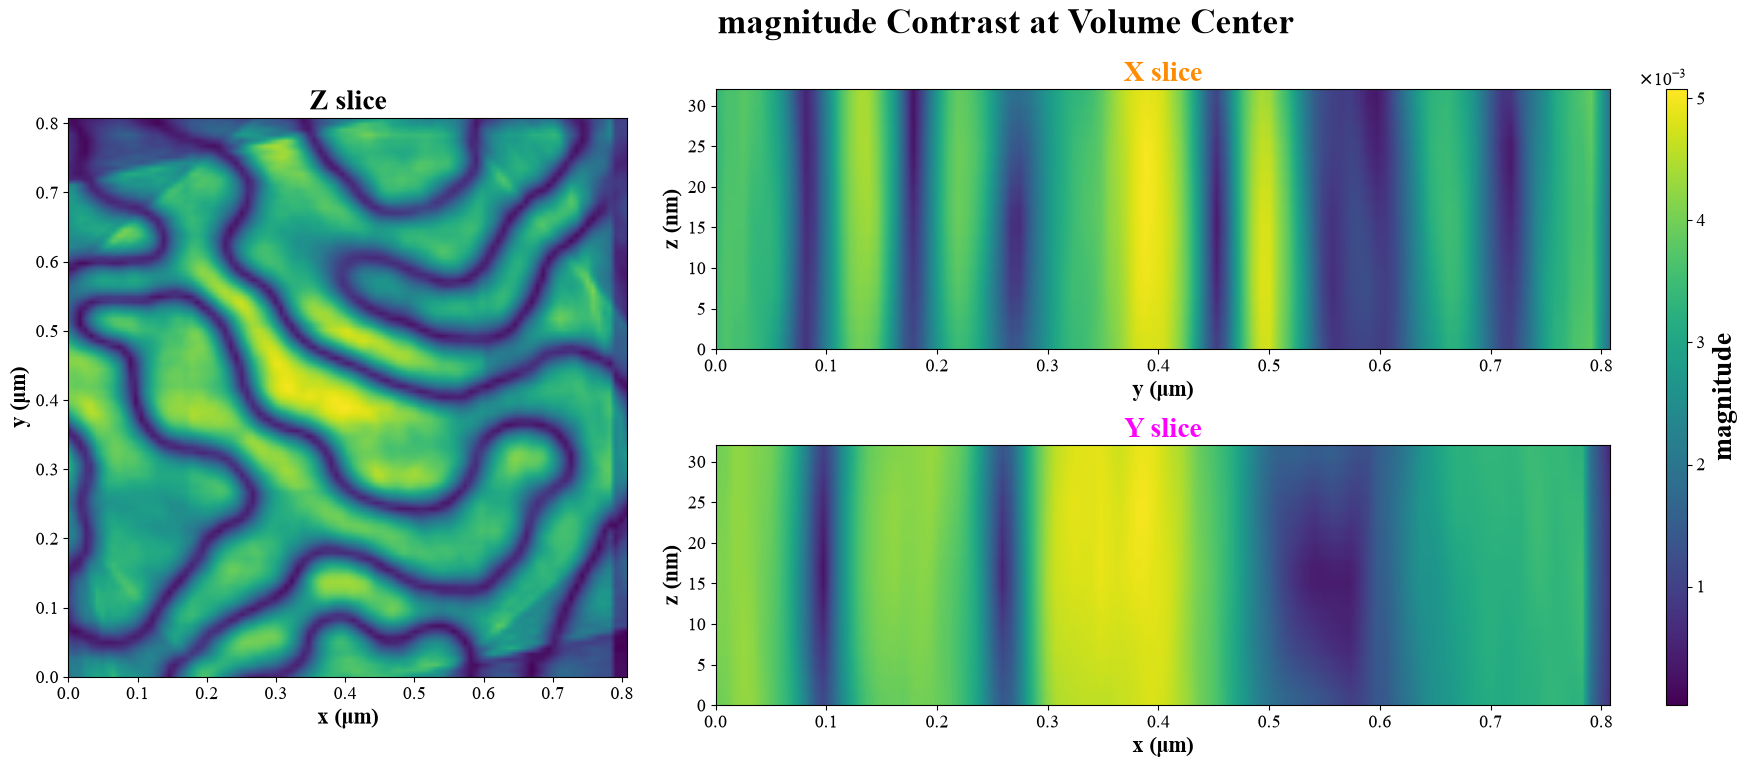

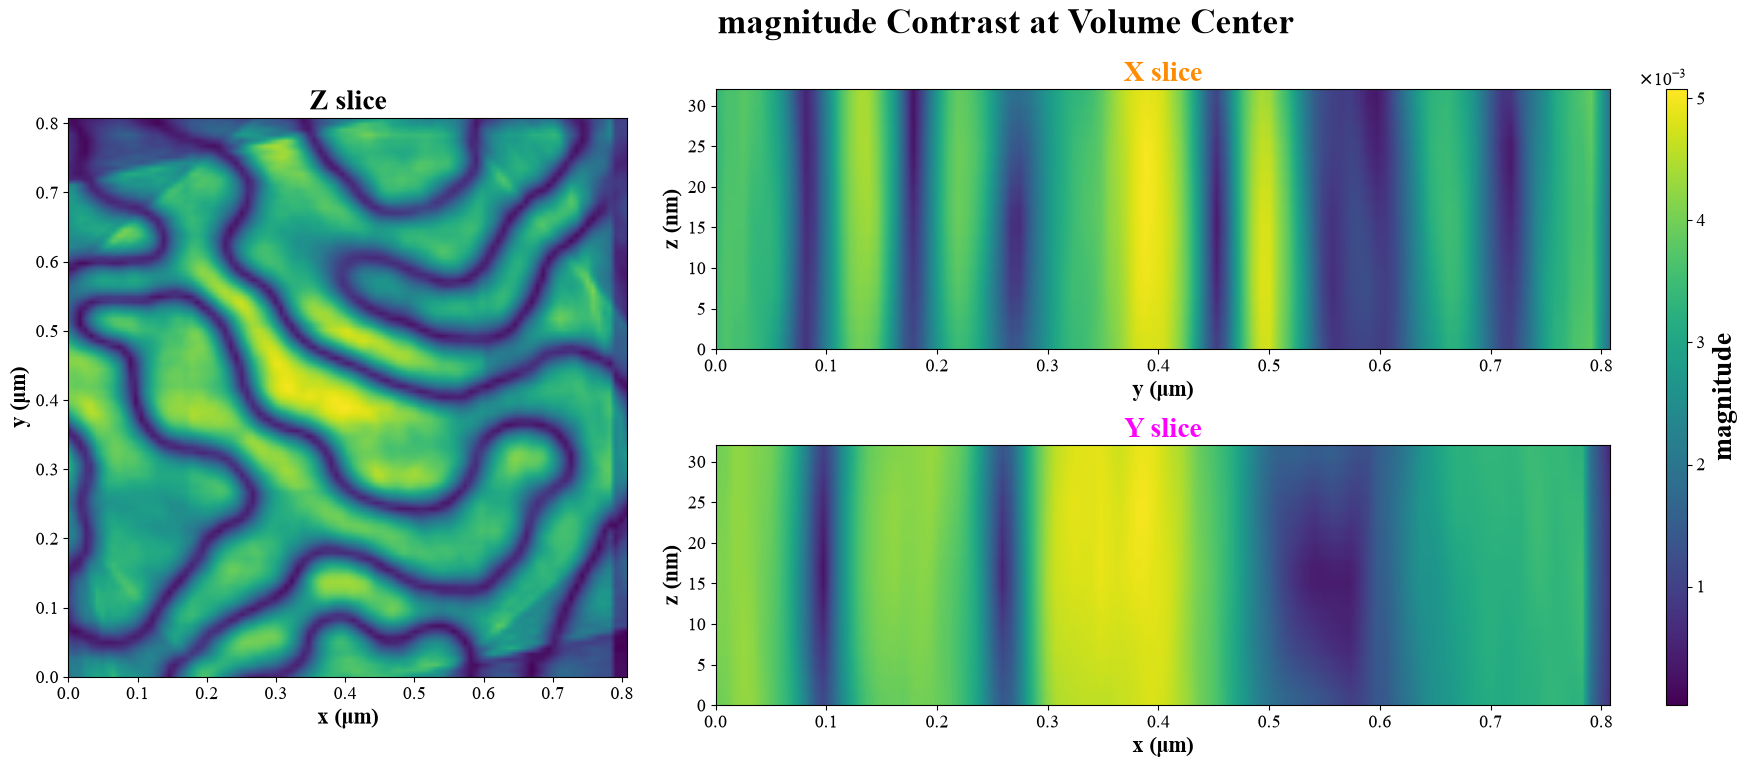

In [13]:
vis.plot_three_slice_fancy(samples[sample_name]['cropped'], field='Mx')
vis.plot_three_slice_fancy(samples[sample_name]['cropped'], field='My')
vis.plot_three_slice_fancy(samples[sample_name]['cropped'], field='Mz')
vis.plot_three_slice_fancy(samples[sample_name]['cropped'], field='Magnitude')
# plot_three_slice(samples[sample_name]['cropped'], field='My', x_index=33, y_index=33)
# plot_three_slice(samples[sample_name]['cropped'], field='Mz', x_index=75, y_index=75)

# smooth

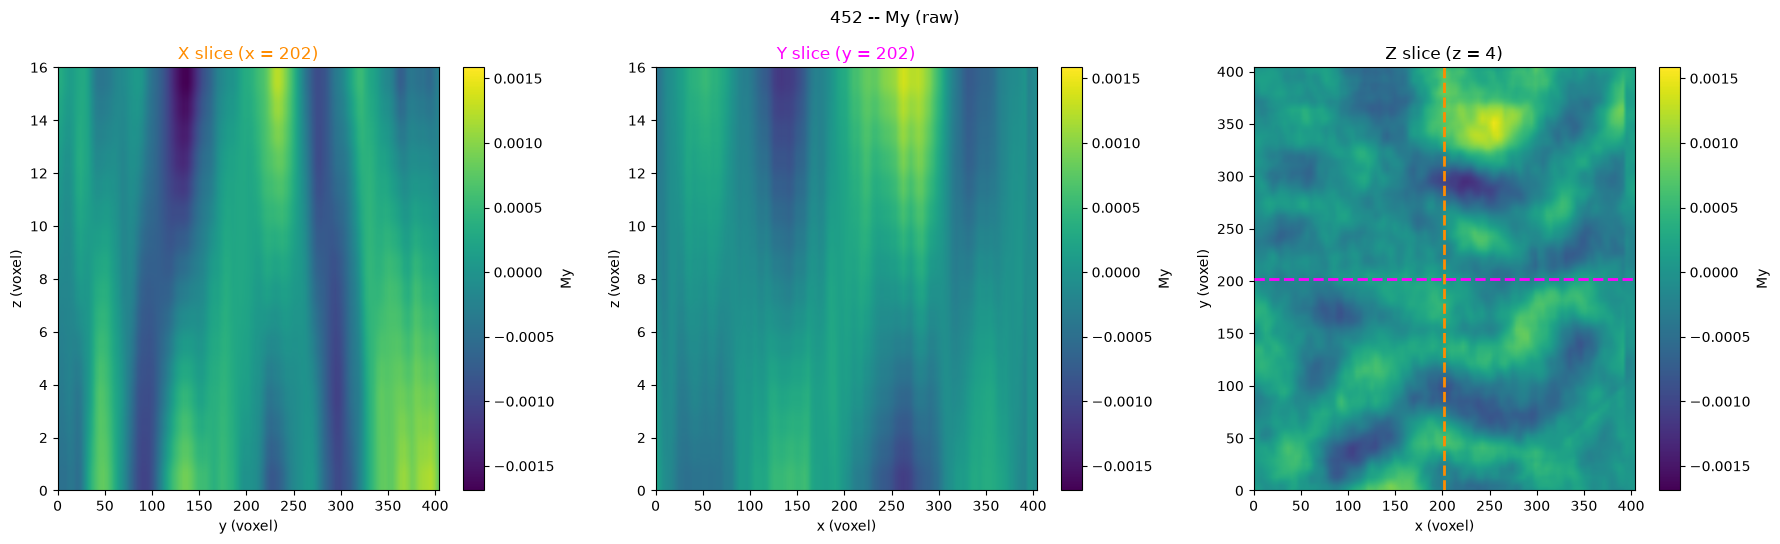

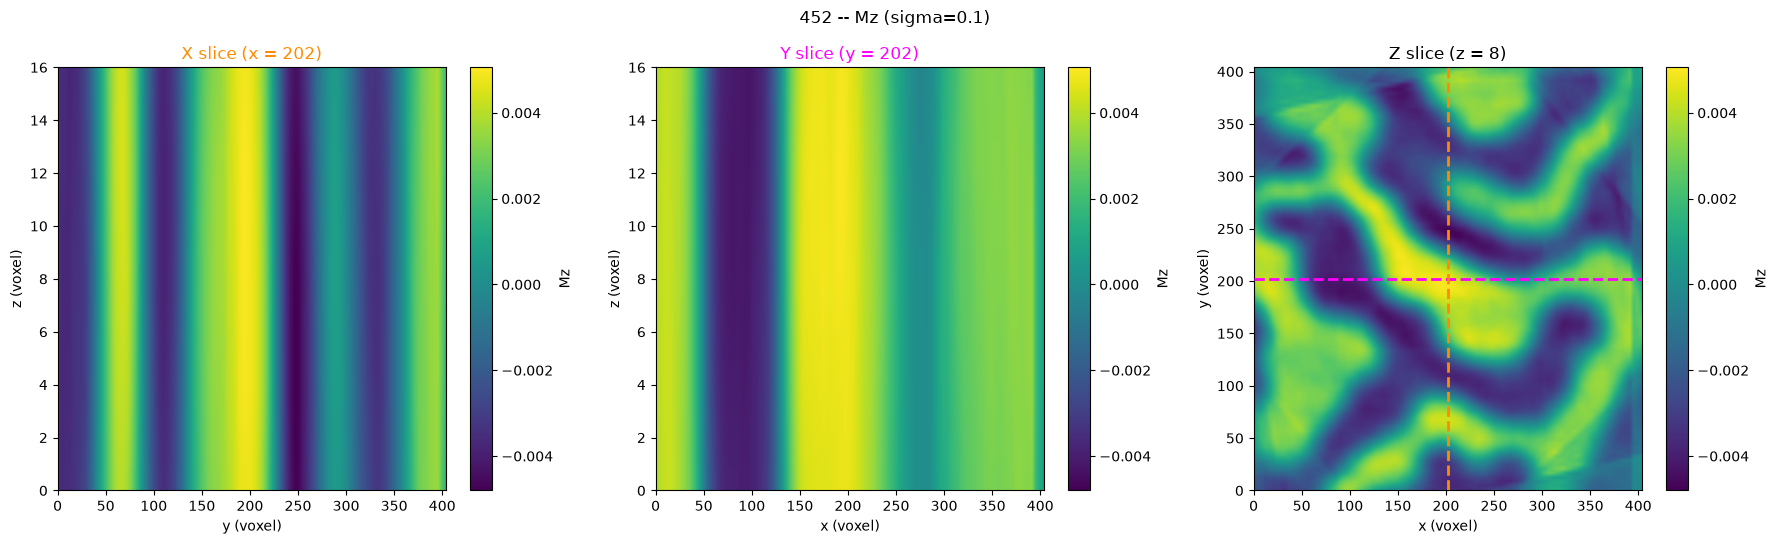

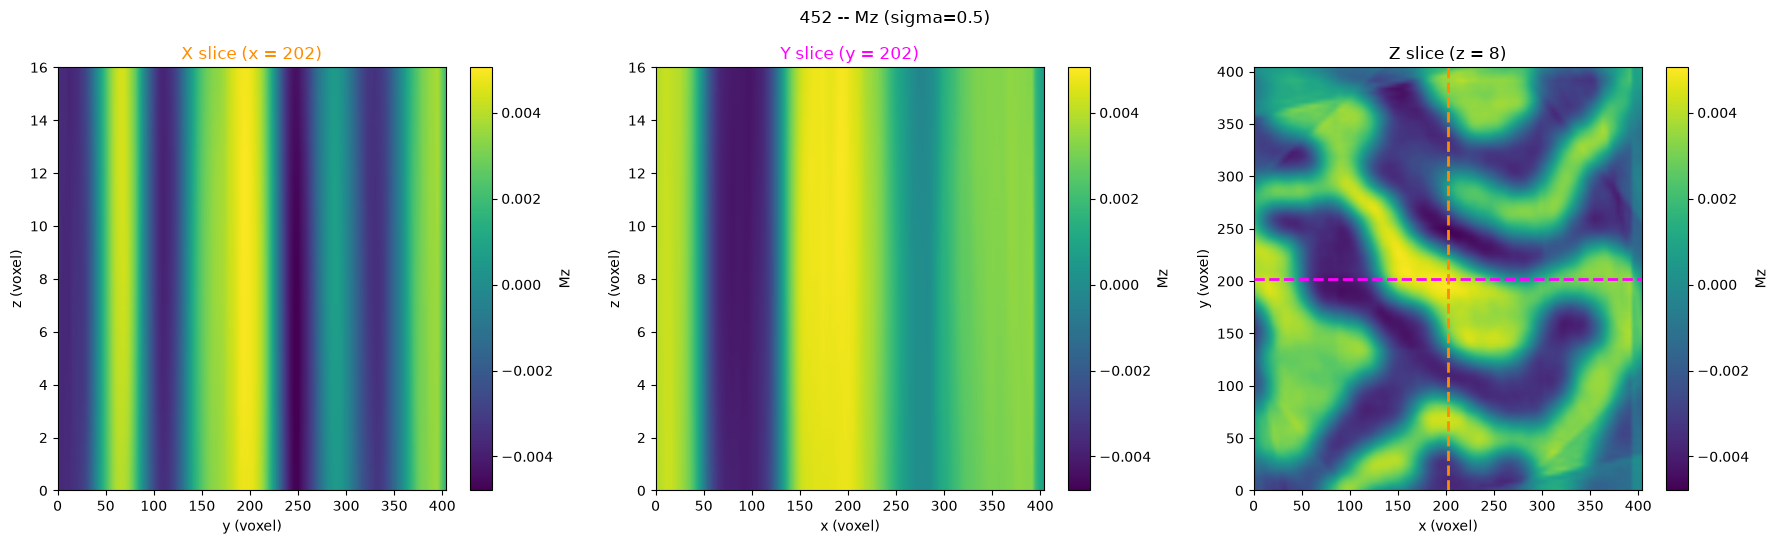

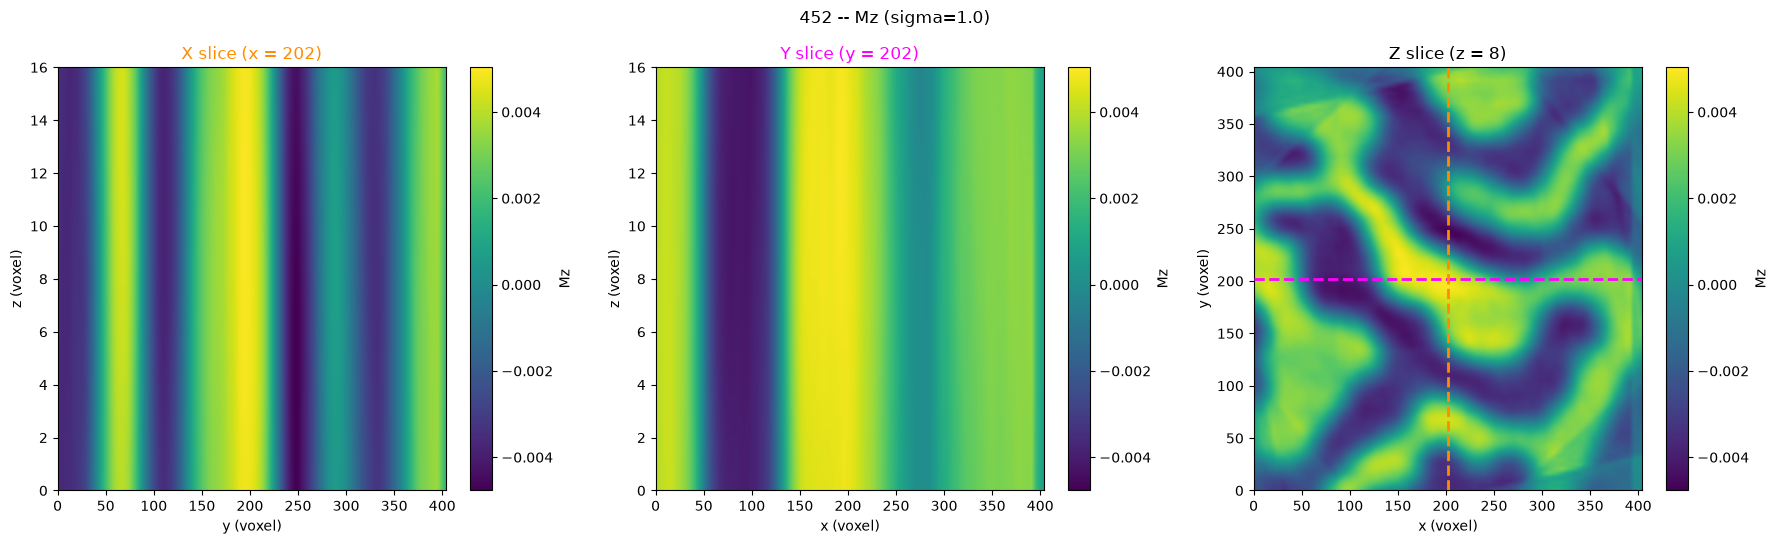

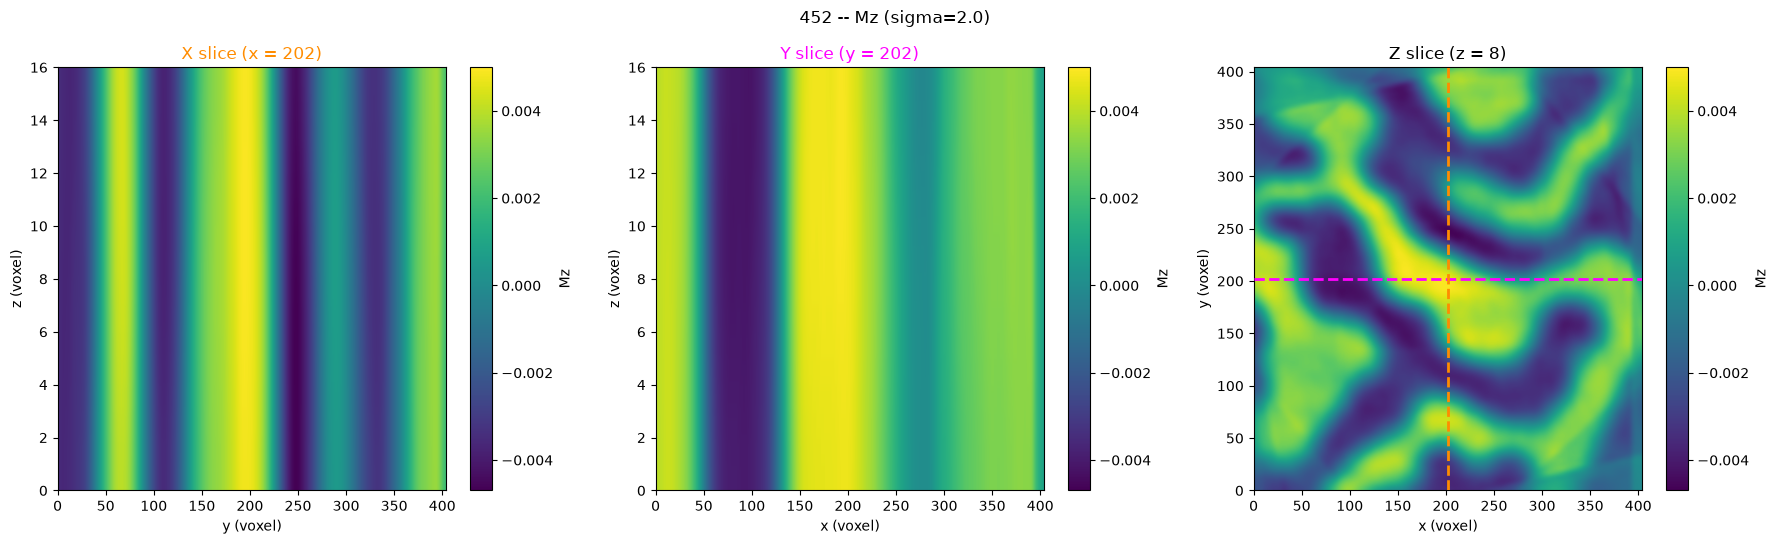

In [14]:
# Raw, unsmoothed (same as before)
vis.apply_gaussian_blur_and_view(samples[sample_name]['cropped'], field='My', z_index=4)

sigmas_to_test = [0.1, 0.5, 1.0, 2.0]

for s in sigmas_to_test:
    vis.apply_gaussian_blur_and_view(samples[sample_name]['cropped'], field='Mz', sigma=s)


############## SELECT SIGMA TO SAVE ##############
sigma_save = 0.5
Mz_smooth = samples[sample_name]['cropped']['smoothed']['Mz'][sigma_save]
##################################################

# Save Cropped Data! 

In [15]:
stop

NameError: name 'stop' is not defined

In [16]:
date_save = 'og_interpolated'

In [17]:
def save_sample_data(save_dir, sample_name, cropped, spacing=(2.0, 2.0, 2.0), date = None):
    """
    Save the cropped volume and wall-analysis DataFrame for one sample,
    in a format suitable for later cross-sample/material comparison.

    Parameters
    ----------
    save_dir : str
        Directory to save into (created if it doesn't exist).
    sample_name : str
        Identifier for this sample/material, used in filenames and
        stamped into the saved data for later grouping.
    cropped : dict
        The cropped sample dict, expected to contain 'Mx', 'My', 'Mz',
        'magnitude', and 'shape'.
    wall_df : pd.DataFrame
        The per-vertex wall analysis table (normals, psi, chirality, etc.)
    spacing : tuple
        (dz, dy, dx) physical voxel size, in nm.
    z_offset : int
        Offset applied to bring local z-indices back into the original
        volume's index frame (as discussed earlier).
    Delta : float or None
        Domain wall width parameter, if known/relevant, saved as metadata.
    extra_metadata : dict or None
        Any additional key-value info you want stored alongside (e.g.
        material composition, deposition conditions, notes).
    """
    os.makedirs(save_dir, exist_ok=True)

    # --- Save volume arrays ---
    volume_path = os.path.join(save_dir, f'{sample_name}_volume_{date}.npz')
    np.savez_compressed(
        volume_path,
        Mx=cropped['Mx'], My=cropped['My'], Mz=cropped['Mz'],
        magnitude=cropped['magnitude'],
        shape=np.array(cropped['shape']),
        spacing=np.array(spacing),
    )

    print(f"Saved: {volume_path}")
    return volume_path



save_dir = data_dir

save_sample_data(save_dir, sample_name, samples[sample_name]['cropped'], spacing=(2.0, 2.0, 2.0),  date = date_save)

Saved: C:\Users\emmab\Projects\Vector_Tomography\data_dir\452_orig\452_volume_og_interpolated.npz


'C:\\Users\\emmab\\Projects\\Vector_Tomography\\data_dir\\452_orig\\452_volume_og_interpolated.npz'

In [ ]:
stop

NameError: name 'stop' is not defined

DELETE EVERYTHING BELOW 

# Marching cubes isosurface extraction at Mz = 0

In [ ]:

dz, dy, dx = 8.0, 8.0, 8.0  # nm,
Mz = samples[sample_name]['cropped']['Mz']         # shape (nz, ny, nx)
Mx = samples[sample_name]['cropped']['Mx']
My = samples[sample_name]['cropped']['My']

# spacing here scales the output vertex coordinates and normals into physical
# Level = 0 because this is where the domain wall center is!!! 
verts_phys, faces, normals_phys, values = marching_cubes(Mz_smooth, level=0.0, spacing=(dz, dy, dx), allow_degenerate=True) # Using allow_degenerate=False didn't visually change anything for 452

print(f"Extracted mesh: {verts_phys.shape[0]} vertices, {faces.shape[0]} triangles")

# Convert physical-space vertex coordinates back into fractional voxel-index
# coordinates (z_idx, y_idx, x_idx), since map_coordinates() needs index space.
verts_idx = verts_phys / np.array([dz, dy, dx])

# %% [Cell 5: Interpolate Mx, My, Mz onto mesh vertices]
def sample_volume_at_points(volume, points_idx):
    """
    Trilinear interpolation of `volume` at fractional (z, y, x) index
    coordinates given in points_idx, shape (N, 3).
    """
    coords = points_idx.T  # map_coordinates wants shape (ndim, N)
    return map_coordinates(volume, coords, order=1, mode='nearest')

Mx_v = sample_volume_at_points(Mx, verts_idx)
My_v = sample_volume_at_points(My, verts_idx)
Mz_v = sample_volume_at_points(Mz, verts_idx)  # sample raw (unsmoothed) Mz for the actual physical vector
M_v = np.stack([Mx_v, My_v, Mz_v], axis=1)      # shape (N, 3), order (x, y, z) per vertex

#Correct normal sign convention]
###########  We want normals to consistently point from -Mz domain into +Mz domain.
# Check by sampling Mz slightly ahead of / behind each vertex along its normal.

eps_phys = 8.0  # step size in physical units; scale relative to your voxel size 
eps_idx = eps_phys / np.array([dz, dy, dx])

# normals_phys is in (z, y, x) order to match marching_cubes' internal axis order
step = normals_phys * eps_idx  # broadcast scale per-axis

pts_forward = verts_idx + step
pts_backward = verts_idx - step

Mz_forward = sample_volume_at_points(Mz_smooth, pts_forward)
Mz_backward = sample_volume_at_points(Mz_smooth, pts_backward)

# If moving along +normal decreases Mz, the normal is backwards -- flip it.
flip_mask = Mz_forward < Mz_backward
normals_phys[flip_mask] *= -1

print(f"Flipped {flip_mask.sum()} / {len(flip_mask)} normals to enforce -Mz -> +Mz convention")

# Reorder normals and vertex from (z, y, x) to (x, y, z) for consistency with M_v and PyVista
normals_xyz = normals_phys[:, ::-1]
verts_xyz = verts_phys[:, ::-1]  




NameError: name 'marching_cubes' is not defined

In [ ]:
# Compute Bloch/Néel character angle at each vertex]
M_n = np.einsum('ij,ij->i', M_v, normals_xyz)          # M component along normal
#M_n = np.linalg.norm(M_v, axis=1)
M_t_vec = M_v - M_n[:, None] * normals_xyz
M_t_mag = np.linalg.norm(M_t_vec, axis=1)
psi_unsigned = np.degrees(np.arctan2(M_t_mag, M_n))             # 0/180 = Néel-like, +-90 = Bloch-like

In [ ]:
def add_volume_slice_pv(plotter, sample, field='Mz', axis='z', index=None,
                         sigma=None, spacing=(8.0, 8.0, 8.0),
                         cmap='viridis', opacity=0.7, vmin=None, vmax=None,
                         show_scalar_bar=False):
    """
    Add a single axis-aligned voxel slice of `field` to a PyVista plotter,
    using the same index convention as plot_three_slice (axis + voxel index).

    axis : 'x', 'y', or 'z' -- which axis to slice along
    index : voxel index along that axis (defaults to center)
    sigma : if not None, use the cached smoothed volume at that sigma
            (sample['smoothed'][key][sigma], as populated by plot_three_slice)
    spacing : (dz, dy, dx) physical voxel size, e.g. (8.0, 8.0, 8.0) for your data
    """
    field_aliases = {'mag': 'magnitude', 'magnitude': 'magnitude',
                      'mx': 'Mx', 'my': 'My', 'mz': 'Mz'}
    key = field_aliases.get(field.lower())
    data = sample[key] if sigma is None else sample['smoothed'][key][sigma]

    nz, ny, nx = sample['shape']
    dz, dy, dx = spacing

    if vmin is None:
        vmin = np.nanmin(sample[key])
    if vmax is None:
        vmax = np.nanmax(sample[key])

    # Build the full 3D grid with correctly-ordered cell data
    grid = pv.ImageData()
    grid.dimensions = np.array((nx, ny, nz)) + 1  # point dims = cell dims + 1
    grid.spacing = (dx, dy, dz)
    grid.origin = (0, 0, 0)
    grid.cell_data[key] = data.flatten(order='C')  # corrected order

    # Default index = center of chosen axis, same as plot_three_slice
    default_index = {'x': nx // 2, 'y': ny // 2, 'z': nz // 2}
    if index is None:
        index = default_index[axis]

    normal_map = {'x': (1, 0, 0), 'y': (0, 1, 0), 'z': (0, 0, 1)}
    spacing_map = {'x': dx, 'y': dy, 'z': dz}
    axis_pos_idx = {'x': 0, 'y': 1, 'z': 2}

    # Place the cutting plane at the *center* of the chosen voxel layer,
    # so the cut passes through the middle of those cells and returns their
    # exact values rather than something interpolated between layers.
    origin = [0.0, 0.0, 0.0]
    origin[axis_pos_idx[axis]] = (index + 0.5) * spacing_map[axis]

    sliced = grid.slice(normal=normal_map[axis], origin=tuple(origin))

    plotter.add_mesh(sliced, scalars=key, cmap=cmap, opacity=opacity,
                      clim=[vmin, vmax], show_scalar_bar=show_scalar_bar)
    return sliced

C:\Users\emmab\AppData\Local\Temp\ipykernel_30376\624376577.py:98: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  plotter.show()


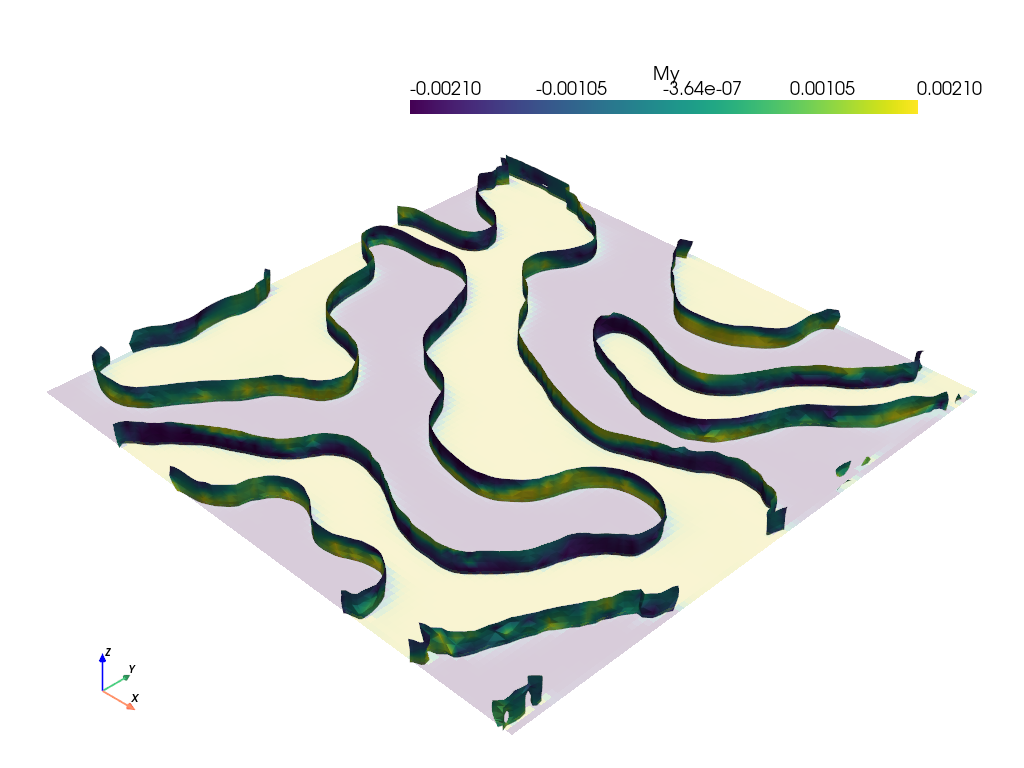

In [ ]:
# PyVista visualization
# Build the triangle mesh in PyVista's expected face format (leading '3' per triangle)
faces_pv = np.hstack([np.full((faces.shape[0], 1), 3), faces]).astype(np.int64)
mesh = pv.PolyData(verts_xyz, faces_pv)
mesh['Normals'] = normals_xyz
mesh['Mn'] = M_n
mesh['psi_deg'] = psi_unsigned
mesh['Mz_at_vertex'] = Mz_v
mesh['Mx'] = Mx_v
mesh['My'] = My_v

plotter = pv.Plotter()




# # # # Wall surface colored by psi character
# sargs = dict(
#     position_x=0.4,  # Move towards the right edge
#     position_y=0.85,   # Move near the bottom
#     height=0.05,       # Make it take up 50% of window height
#     width=0.5,        # Width of the bar
#     vertical=False,    # Orientation
#     title = 'psi (deg): 0/180=Neel, +-90=Bloch'
# )
# plotter.add_mesh(mesh, scalars='psi_deg', cmap='seismic', clim=[0, 90],   # seismic   twilight
#                   scalar_bar_args = sargs)


# # Wall surface colored by Surface normal
# sargs = dict(
#     position_x=0.4,  # Move towards the right edge
#     position_y=0.85,   # Move near the bottom
#     height=0.05,       # Make it take up 50% of window height
#     width=0.5,        # Width of the bar
#     vertical=False,    # Orientation
#     title = 'Surface Normal 0=Bloch, +-Mn=Neel'
# )
# # plotter.add_mesh(mesh, scalars='Mn', cmap='brg', clim=[np.min(values), np.max(values)],   # seismic   twilight
# #                   scalar_bar_args={'title': 'Surface Normal 0=Bloch, +-Mn=Neel'})
# plotter.add_mesh(mesh, scalars='Mn', cmap='brg', clim=[-0.0015, 0.0015],   # seismic   twilight
#                   scalar_bar_args=sargs)



# # Wall surface colored by Mx normal
# sargs = dict(
#     position_x=0.4,  # Move towards the right edge
#     position_y=0.85,   # Move near the bottom
#     height=0.05,       # Make it take up 50% of window height
#     width=0.5,        # Width of the bar
#     vertical=False,    # Orientation
#     title = 'Mx'
# )
# # plotter.add_mesh(mesh, scalars='Mn', cmap='brg', clim=[np.min(values), np.max(values)],   # seismic   twilight
# #                   scalar_bar_args={'title': 'Surface Normal 0=Bloch, +-Mn=Neel'})
# plotter.add_mesh(mesh, scalars='Mx', cmap='viridis', clim=[np.min(Mx_v), np.max(Mx_v)],   # seismic   twilight
#                   scalar_bar_args=sargs)


# Wall surface colored by My normal
sargs = dict(
    position_x=0.4,  # Move towards the right edge
    position_y=0.85,   # Move near the bottom
    height=0.05,       # Make it take up 50% of window height
    width=0.5,        # Width of the bar
    vertical=False,    # Orientation
    title = 'My'
)
# plotter.add_mesh(mesh, scalars='Mn', cmap='brg', clim=[np.min(values), np.max(values)],   # seismic   twilight
#                   scalar_bar_args={'title': 'Surface Normal 0=Bloch, +-Mn=Neel'})
plotter.add_mesh(mesh, scalars='My', cmap='viridis', clim=[np.min(My_v), np.max(My_v)],   # seismic   twilight
                  scalar_bar_args=sargs)



# # Overlay normal vectors as arrows, subsampled so the plot isn't overwhelmed
# glyph_mesh = mesh.glyph(orient='Normals', scale=False, factor=3.0,
#                          geom=pv.Arrow(), tolerance=0.05)  # tolerance subsamples points
# plotter.add_mesh(glyph_mesh, color='black')

# Optional: add a volume slice for spatial context within the full sample
grid = pv.ImageData()
grid.dimensions = np.array(Mz.shape[::-1]) + 1   # (Mz = samples[sample_name]['cropped']['Mz'] )
# print(np.array(Mz.shape[::-1]) +1 )
grid.spacing = (dx, dy, dz)
grid.origin = (0, 0, 0)
grid.cell_data['Mz'] = Mz.flatten(order='C')  # note: flatten order matters, check orientation
#plotter.add_mesh(grid.slice(normal='y'), cmap='viridis', opacity=0.75, show_scalar_bar=False)
# add_volume_slice_pv(plotter, samples[sample_name]['cropped'], field='Mz', axis='y', index=33)
add_volume_slice_pv(plotter, samples[sample_name]['cropped'], field='Mz', axis='z', index=0, opacity=0.2)  # defaults to center


plotter.view_isometric()      # view_isometric   view_xy
plotter.camera.zoom(1.25)
plotter.camera.azimuth += 270
plotter.add_axes()
plotter.show()


# Chirality calculation

In [ ]:
def compute_chirality_angle(M_v, normals_xyz, up_axis=np.array([0.0, 0.0, 1.0])):
    """
    Compute a signed angle capturing both wall type (Neel vs Bloch) and
    chirality (rotation sense), for each mesh vertex.

    Parameters
    ----------
    M_v : (N, 3) array
        Magnetization vectors at each mesh vertex (x, y, z order).
    normals_xyz : (N, 3) array
        Wall normal vectors at each mesh vertex (x, y, z order), already
        sign-corrected to point from -Mz into +Mz domain.
    up_axis : (3,) array
        Reference axis used to define tangential direction, defaults to
        the film's easy axis (z), appropriate for PMA films.

    Returns
    -------
    psi_chiral : (N,) array, degrees, range (-180, 180]
        0 deg   -> Neel, pointing along +n_hat
        180 deg -> Neel, pointing along -n_hat (opposite polarity)
        +90 deg -> Bloch, curling in +t_hat direction
        -90 deg -> Bloch, curling in -t_hat direction
    t_hat : (N, 3) array
        The tangential unit vector used at each vertex, in case you want
        to visualize it directly (e.g. as arrows alongside the normals).
    degenerate_mask : (N,) bool array
        True where n_hat was parallel to up_axis, making t_hat undefined
        (chirality is meaningless there; check how many/where this occurs).
    """
    up = np.broadcast_to(up_axis, normals_xyz.shape)
    t_vec = np.cross(up, normals_xyz)  # automatically perpendicular to normals_xyz
    t_norm = np.linalg.norm(t_vec, axis=1)

    degenerate_mask = t_norm < 1e-8
    if np.any(degenerate_mask):
        print(f"Warning: {degenerate_mask.sum()} / {len(degenerate_mask)} vertices "
              f"have normals parallel to up_axis; chirality undefined there.")
        t_norm = np.where(degenerate_mask, 1.0, t_norm)  # avoid divide-by-zero

    t_hat = t_vec / t_norm[:, None]

    M_n = np.einsum('ij,ij->i', M_v, normals_xyz)   # signed, along normal
    M_t_signed = np.einsum('ij,ij->i', M_v, t_hat)   # signed, along tangent

    psi_chiral = np.degrees(np.arctan2(M_t_signed, M_n))

    return psi_chiral, t_hat, degenerate_mask

In [ ]:
def plot_map(sample, verts_xyz, faces, key_to_map, bounds = 180,  cmap='seismic',
                        show_grid = True, field = 'Mz',
                        show_normals=False, normals_xyz=None,
                        show_tangents=False, t_hat=None, glyph_factor=3.0,
                        glyph_tolerance=0.05):
    """
    Visualize the signed chirality/wall-type angle on the domain wall mesh.

    Parameters
    ----------
    verts_xyz, faces : mesh geometry, as produced by marching_cubes
    psi_chiral : (N,) array, degrees, from compute_chirality_angle
    cmap : colormap; 'twilight' or 'hsv' are good choices since they're
        cyclic and represent the wraparound at +-180 deg without a
        visually misleading hard color jump
    show_normals, show_tangents : optionally overlay arrows for n_hat
        and/or t_hat (pass normals_xyz / t_hat if enabling these)
    """
    faces_pv = np.hstack([np.full((faces.shape[0], 1), 3), faces]).astype(np.int64)
    mesh = pv.PolyData(verts_xyz, faces_pv)
    mesh['key_to_map'] = key_to_map

    plotter = pv.Plotter()
    plotter.add_mesh(
        mesh, scalars='key_to_map', cmap=cmap, clim=[-bounds, bounds],
        #scalar_bar_args={'title': 'psi (deg): 0/180=Neel, +-90=Bloch (sign=chirality)'}
    )

    if show_normals and normals_xyz is not None:
        mesh['Normals'] = normals_xyz
        glyphs_n = mesh.glyph(orient='Normals', scale=False,
                               factor=glyph_factor, geom=pv.Arrow(),
                               tolerance=glyph_tolerance)
        plotter.add_mesh(glyphs_n, color='black')

    if show_tangents and t_hat is not None:
        mesh['Tangents'] = t_hat
        glyphs_t = mesh.glyph(orient='Tangents', scale=False,
                               factor=glyph_factor, geom=pv.Arrow(),
                               tolerance=glyph_tolerance)
        plotter.add_mesh(glyphs_t, color='green')


    if show_grid: 
        M = sample[field]
        grid = pv.ImageData()
        grid.dimensions = np.array(Mz.shape[::-1]) + 1   # (Mz = samples[sample_name]['cropped']['Mz'] )
        # print(np.array(Mz.shape[::-1]) +1 )
        grid.spacing = (8.0, 8.0, 8.0) #################### HARD CODED FOR 8nm VOXEL SIZE 
        grid.origin = (0, 0, 0)
        grid.cell_data['Mz'] = Mz.flatten(order='C')  # note: flatten order matters, check orientation
        add_volume_slice_pv(plotter, sample, field='Mz', axis='z', index=0, opacity=0.2)  # defaults to center

    plotter.add_axes()
    plotter.show()
    return mesh


In [ ]:
psi_chiral, t_hat, degenerate_mask = compute_chirality_angle(M_v, normals_xyz)

C:\Users\emmab\AppData\Local\Temp\ipykernel_30376\689559688.py:55: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  plotter.show()


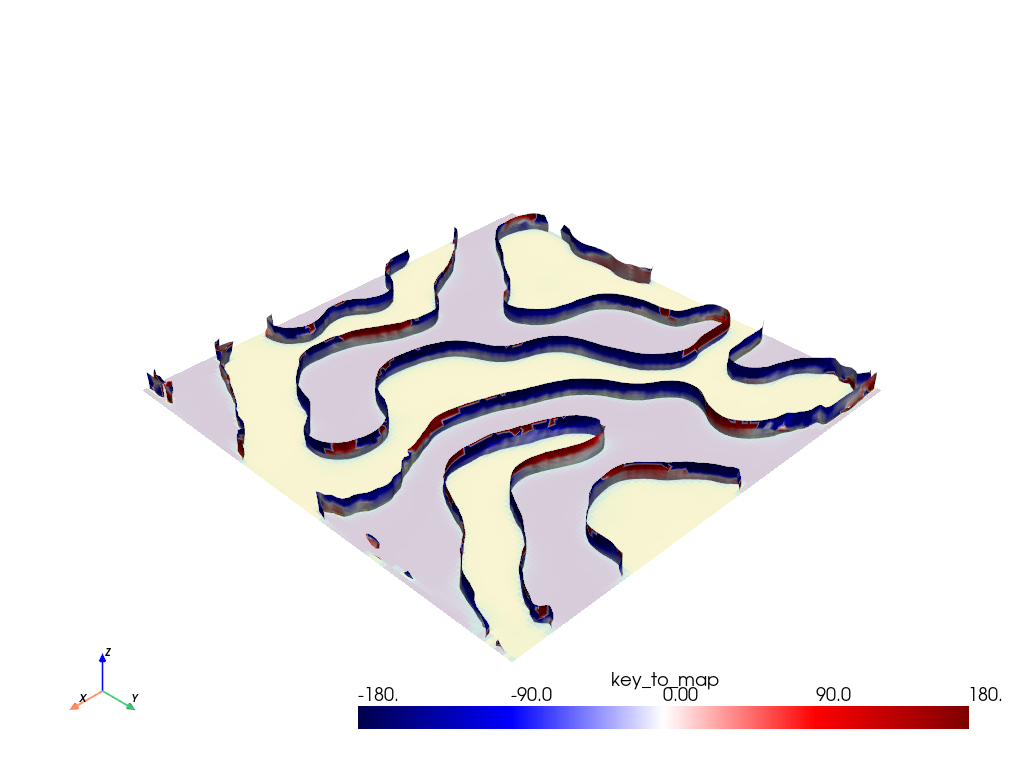

PolyData (0x18cf84e8b80)
  N Cells:    9094
  N Points:   5687
  N Strips:   0
  X Bounds:   0.000e+00, 8.000e+02
  Y Bounds:   0.000e+00, 8.000e+02
  Z Bounds:   0.000e+00, 3.200e+01
  N Arrays:   1

In [ ]:
plot_map(samples[sample_name]['cropped'], verts_xyz, faces, psi_chiral, cmap='seismic')

# highlight Bloch and Neel

In [ ]:
def classify_pure_bloch_neel(wall_df, method='normal', tol=None, z_offset_included=True):
    """
    Classify wall vertices as 'bloch', 'neel', or 'unclassified' using one
    of two strict criteria.

    Parameters
    ----------
    wall_df : pd.DataFrame
        Must contain Mx, My, Mz, nx, ny, nz (and ix, iy, iz / x, y, z for
        location bookkeeping).
    method : 'normal' or 'psi'
        'normal' -- classify using M_n = M.n_hat directly.
            Bloch: |M_n| < tol           (tangential, no normal component)
            Neel:  |M_n| within tol of |M| (fully radial/along normal)
        'psi' -- classify using the unsigned wall-type angle, computed in
            RADIANS directly from M_n and the tangential magnitude (not
            the pre-computed degree column, to avoid round-trip error).
            Bloch: |psi_rad - pi/2| < tol
            Neel:  psi_rad within tol of 0 or pi
    tol : float
        Tolerance for the chosen method. Recommended: 0.0005 for 'normal'
        (dimensionless, dot-product units), 0.005 for 'psi' (radians).
    z_offset_included : bool
        Set True if wall_df['iz'] already reflects true experimental
        voxel numbering (as it should if you applied z_offset earlier).
        This is just a bookkeeping flag/reminder, not used in the math.

    Returns
    -------
    df : pd.DataFrame
        Copy of wall_df with an added 'category' column
        ('bloch' / 'neel' / 'unclassified') and the raw comparison
        quantity used (M_n and mag, or psi_rad) as new columns.
    """
    df = wall_df.copy()
    Mx, My, Mz = df['Mx'].values, df['My'].values, df['Mz'].values
    nx_, ny_, nz_ = df['nx'].values, df['ny'].values, df['nz'].values
    M_v = np.stack([Mx, My, Mz], axis=1)
    n_v = np.stack([nx_, ny_, nz_], axis=1)

    M_n = np.einsum('ij,ij->i', M_v, n_v)
    mag_v = np.linalg.norm(M_v, axis=1)

    category = np.full(len(df), 'unclassified', dtype=object)

    if method == 'normal':
        tol = 0.0005 if tol is None else tol
        is_bloch = np.abs(M_n) < tol
        is_neel = np.abs(np.abs(M_n) - mag_v) < tol
        df['M_n'] = M_n
        df['mag'] = mag_v

    elif method == 'psi':
        tol = 0.005 if tol is None else tol
        M_t_vec = M_v - M_n[:, None] * n_v
        M_t_mag = np.linalg.norm(M_t_vec, axis=1)
        psi_rad = np.arctan2(M_t_mag, M_n)  # range [0, pi]
        is_bloch = np.abs(psi_rad - np.pi / 2) < tol
        is_neel = (np.abs(psi_rad - 0.0) < tol) | (np.abs(psi_rad - np.pi) < tol)
        df['psi_rad'] = psi_rad

    else:
        raise ValueError("method must be 'normal' or 'psi'")

    category[is_bloch] = 'bloch'
    category[is_neel] = 'neel'
    overlap = is_bloch & is_neel
    if overlap.any():
        print(f"Warning: {overlap.sum()} vertices satisfied both criteria "
              f"simultaneously (tol may be too loose, or |M| is near zero "
              f"there); labeled as 'bloch' by default overwrite order.")

    df['category'] = category
    n_bloch, n_neel = (category == 'bloch').sum(), (category == 'neel').sum()
    print(f"[{method}] tol={tol}: {n_bloch} bloch, {n_neel} neel, "
          f"{len(df) - n_bloch - n_neel} unclassified (of {len(df)} total)")

    return df

In [ ]:
def plot_pure_bloch_neel_3d(mesh_verts_xyz, classified_df,
                             bloch_color='magenta', neel_color='cyan',
                             show_unclassified=True, point_size=6):
    """
    3D PyVista scatter of classified wall vertices.
    mesh_verts_xyz : (N, 3) array matching classified_df row order
        (i.e. the same verts_xyz used to build wall_df originally).
    """
    plotter = pv.Plotter()

    is_bloch = (classified_df['category'] == 'bloch').values
    is_neel = (classified_df['category'] == 'neel').values
    is_other = ~(is_bloch | is_neel)

    if show_unclassified and is_other.any():
        plotter.add_points(mesh_verts_xyz[is_other], color='lightgray',
                            point_size=point_size * 0.5, opacity=0.15,
                            render_points_as_spheres=True)

    if is_bloch.any():
        plotter.add_points(mesh_verts_xyz[is_bloch], color=bloch_color,
                            point_size=point_size, render_points_as_spheres=True,
                            label='Bloch (pure)')
    if is_neel.any():
        plotter.add_points(mesh_verts_xyz[is_neel], color=neel_color,
                            point_size=point_size, render_points_as_spheres=True,
                            label='Neel (pure)')

    plotter.add_legend()
    plotter.add_axes()
    plotter.show()

In [ ]:
def extract_pure_locations(classified_df):
    """
    Pull out (x, y, z) physical coords and iz (true experimental voxel
    layer) for bloch and neel vertices separately.
    """
    cols = ['x', 'y', 'z', 'ix', 'iy', 'iz']
    bloch_locs = classified_df[classified_df['category'] == 'bloch'][cols].copy()
    neel_locs = classified_df[classified_df['category'] == 'neel'][cols].copy()
    return bloch_locs, neel_locs

# Save iso cut in a dataframe

In [ ]:
def build_wall_dataframe(verts_xyz, normals_xyz, t_hat, M_v,
                          psi_unsigned, psi_chiral, M_normal, degenerate_mask,
                          spacing=(8.0, 8.0, 8.0)):
    """
    Consolidate all per-vertex wall quantities into a single tidy DataFrame,
    one row per mesh vertex. spacing = (dz, dy, dx) in physical units, used
    to also store voxel-index coordinates for binning/slicing by layer.
    """
    dz, dy, dx = spacing
    df = pd.DataFrame({
        'x': verts_xyz[:, 0], 'y': verts_xyz[:, 1], 'z': verts_xyz[:, 2],
        'ix': verts_xyz[:, 0] / dx, 'iy': verts_xyz[:, 1] / dy, 'iz': verts_xyz[:, 2] / dz,
        'nx': normals_xyz[:, 0], 'ny': normals_xyz[:, 1], 'nz': normals_xyz[:, 2],
        'tx': t_hat[:, 0], 'ty': t_hat[:, 1], 'tz': t_hat[:, 2],
        'Mx': M_v[:, 0], 'My': M_v[:, 1], 'Mz': M_v[:, 2],
        'M_normal': M_n,
        'psi_unsigned': psi_unsigned,
        'psi_chiral': psi_chiral,
        'degenerate': degenerate_mask,
    })
    df['vertex_id'] = df.index
    return df

wall_df = build_wall_dataframe(verts_xyz, normals_xyz, t_hat, M_v,
                                psi_unsigned, psi_chiral, M_n, degenerate_mask)

In [ ]:
print(Mz_smooth.shape) 

(5, 101, 101)


In [ ]:
# mesh.point_data['psi_unsigned'] = psi_unsigned
# mesh.point_data['psi_chiral'] = psi_chiral
# mesh.point_data['nx'], mesh.point_data['ny'], mesh.point_data['nz'] = normals_xyz.T
# mesh.point_data['Mz'] = M_v[:, 2]

# Analyze iso surfaces

5687 / 5687 vertices fall within layers 0-5
[45]


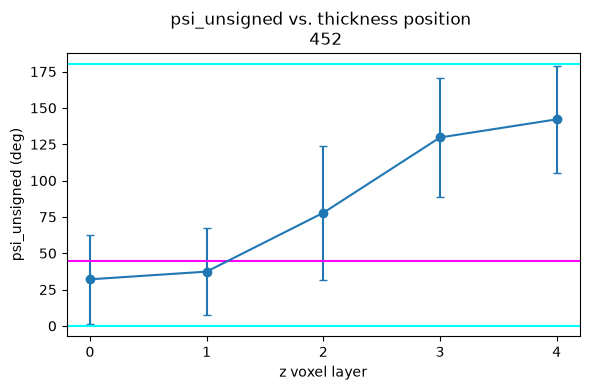

5687 / 5687 vertices fall within layers 0-5
[-45, 45]


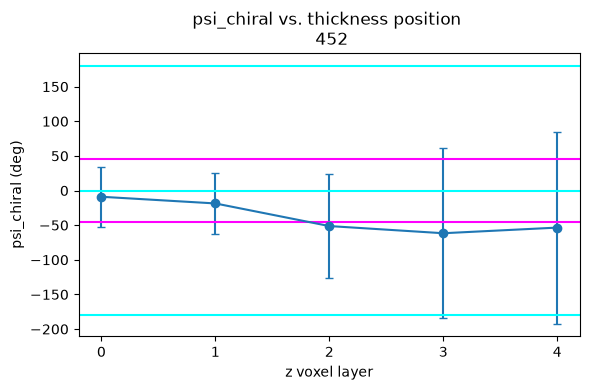

5687 / 5687 vertices fall within layers 0-5
[0]


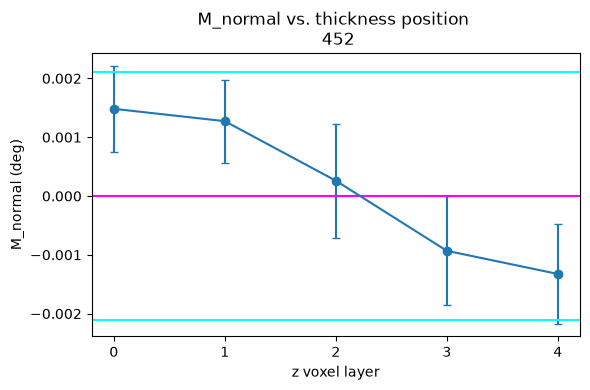

,mean,std,count
z_layer,,,
0,0.001483,0.000730,1137
1,0.001273,0.000707,1147
2,0.000261,0.000969,1139
3,-0.000932,0.000925,1144
4,-0.001326,0.000844,1120


In [ ]:
def plot_angle_vs_z(wall_df, bounds, angle_col='psi_chiral',  bloch_axis = None , neel_axis = None , title = None):
    df = wall_df.copy()
    z_lo, z_hi = bounds
    z_min = z_lo - z_lo
    z_max = z_hi - z_lo
   

    df['z_layer'] = df['iz'].round().astype(int)
    # print(df['iz'].min(), df['iz'].max())
    # print(df['z_layer'].value_counts().sort_index() if 'z_layer' in df else 'not yet computed')

    # Restrict to the physical film thickness, excluding any background/
    # padding layers from the tomography reconstruction.
    n_before = len(df)
    df = df[(df['z_layer'] >= z_min) & (df['z_layer'] <= z_max)]
    print(f"{len(df)} / {n_before} vertices fall within layers {z_min}-{z_max}")


    grouped = df.groupby('z_layer')[angle_col].agg(['mean', 'std', 'count'])

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.errorbar(grouped.index, grouped['mean'], yerr=grouped['std'],
                fmt='o-', capsize=3)

    if bloch_axis== None:
        print('no axis')
    else:
        print(bloch_axis)
        for deg in bloch_axis: 
            ax.axhline(deg, color = 'magenta', label = 'Bloch Wall')
        for deg in neel_axis:
            ax.axhline(deg, color = 'cyan', label = 'Neel Wall')
    ax.set_xlabel('z voxel layer')
    ax.set_xticks(range(z_min, z_max))
    ax.set_ylabel(f'{angle_col} (deg)')
    ax.set_title(f'{angle_col} vs. thickness position \n {title}')
    # plt.legend()
    plt.tight_layout()
    plt.show()
    return grouped

bounds = samples[sample_name]['cropped']['crop_z_index_range'] 
plot_angle_vs_z(wall_df, bounds,angle_col='psi_unsigned',  bloch_axis = [45] , neel_axis = [0, 180], title = sample_name )
plot_angle_vs_z(wall_df,bounds, angle_col='psi_chiral', bloch_axis = [-45, 45] , neel_axis = [-180, 0, 180], title = sample_name)
plot_angle_vs_z(wall_df,bounds, angle_col='M_normal', bloch_axis = [0] , neel_axis = [np.min(Mz), np.max(Mz)], title = sample_name )

[normal] tol=5e-05: 64 bloch, 1163 neel, 4460 unclassified (of 5687 total)
[psi] tol=0.1: 150 bloch, 292 neel, 5245 unclassified (of 5687 total)


C:\Users\emmab\AppData\Local\Temp\ipykernel_30376\2151229276.py:31: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  plotter.show()


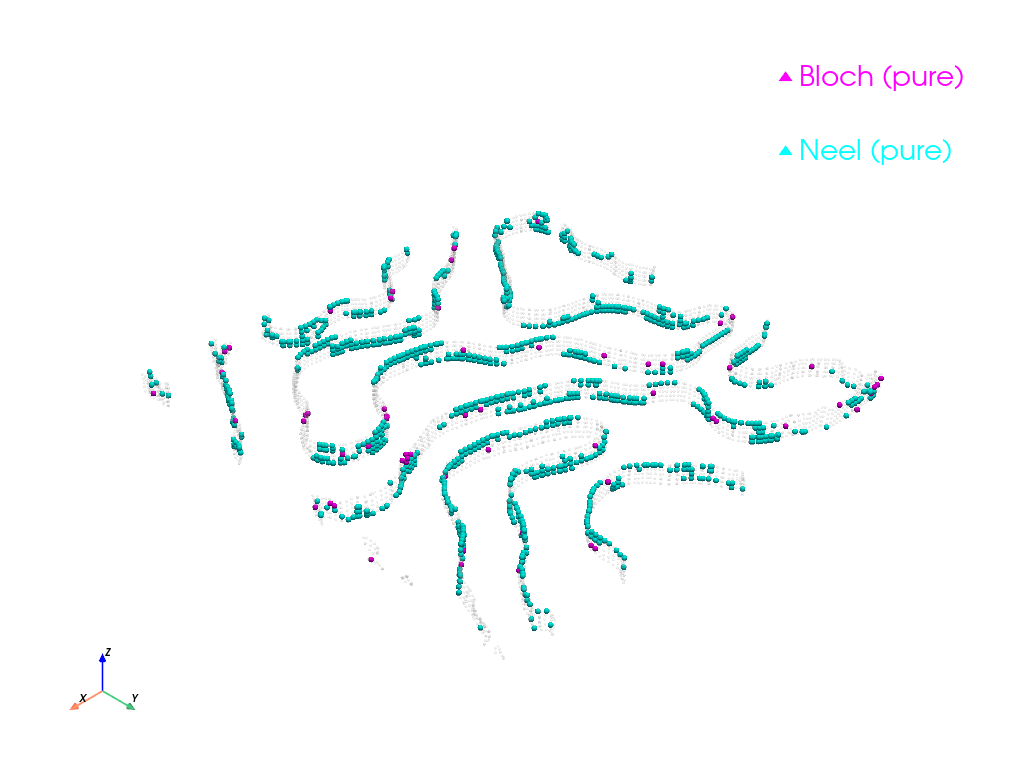

C:\Users\emmab\AppData\Local\Temp\ipykernel_30376\2151229276.py:31: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  plotter.show()


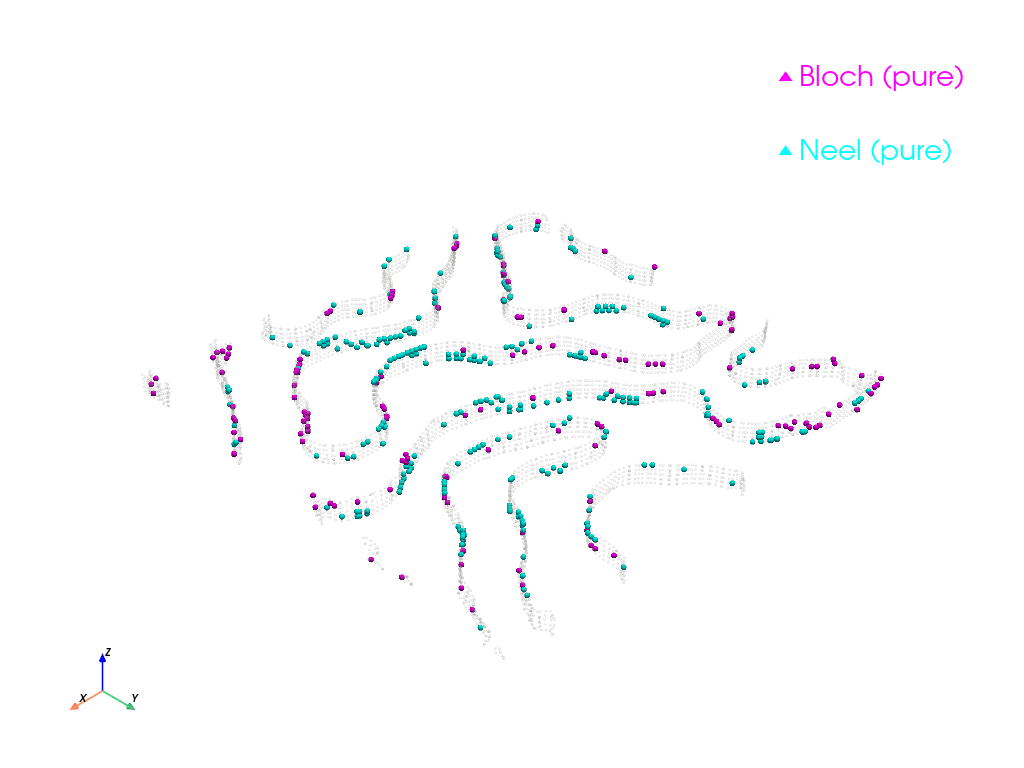

In [ ]:
classified_normal = classify_pure_bloch_neel(wall_df, method='normal', tol=0.00005)
bloch_normal_locs, neel_normal_locs = extract_pure_locations(classified_normal)

classified_psi = classify_pure_bloch_neel(wall_df, method='psi', tol=0.1)
bloch_psi_locs, neel_psi_locs = extract_pure_locations(classified_psi)

plot_pure_bloch_neel_3d(verts_xyz, classified_normal)
plot_pure_bloch_neel_3d(verts_xyz, classified_psi)

In [ ]:


def compute_arclength_per_layer(wall_df, z_bin_size=1.0):
    """
    For each z-layer, order the wall vertices along their in-plane (x, y)
    trace and assign an arc-length coordinate s. Returns wall_df with an
    added 's' column (NaN where a layer has too few points to order).
    """
    df = wall_df.copy()
    df['z_bin'] = (df['z'] / z_bin_size).round() * z_bin_size
    df['s'] = np.nan

    for z_val, group in df.groupby('z_bin'):
        if len(group) < 3:
            continue
        pts = group[['x', 'y']].values
        centroid = pts.mean(axis=0)
        angles = np.arctan2(pts[:, 1] - centroid[1], pts[:, 0] - centroid[0])
        order = np.argsort(angles)  # crude ordering; fine for a single closed/simple wall trace
        ordered_idx = group.index.values[order]
        ordered_pts = pts[order]
        seg_lengths = np.linalg.norm(np.diff(ordered_pts, axis=0), axis=1)
        s_vals = np.concatenate([[0], np.cumsum(seg_lengths)])
        df.loc[ordered_idx, 's'] = s_vals

    return df

def plot_unrolled_wall(wall_df, angle_col='psi_chiral', z_bin_size=1.0, cmap='twilight'):
    df = compute_arclength_per_layer(wall_df, z_bin_size)
    fig, ax = plt.subplots(figsize=(8, 5))
    sc = ax.scatter(df['s'], df['z'], c=df[angle_col], cmap=cmap,
                     vmin=-180 if 'chiral' in angle_col else 0,
                     vmax=180, s=15)
    fig.colorbar(sc, ax=ax, label=f'{angle_col} (deg)')
    ax.set_xlabel('arc length along wall, s (nm)')
    ax.set_ylabel('z (nm, thickness)')
    ax.set_title(f'Unrolled wall: {angle_col}')
    plt.tight_layout()
    plt.show()
    return df


def plot_slice_with_wall_overlay(sample, wall_df, field='Mz', axis='z', index=None,
                                  angle_col='psi_chiral', spacing=(8.0, 8.0, 8.0),
                                  tol=4.0, cmap_field='viridis', cmap_angle='seismic'):
    """
    Plot a 2D voxel slice (matching plot_three_slice conventions) with an
    overlay of wall_df points lying within `tol` (physical units) of that
    slice plane, colored by angle_col.
    """
    field_aliases = {'mag': 'magnitude', 'magnitude': 'magnitude',
                      'mx': 'Mx', 'my': 'My', 'mz': 'Mz'}
    key = field_aliases.get(field.lower())
    data = sample[key]
    nz, ny, nx = sample['shape']
    dz, dy, dx = spacing

    default_index = {'x': nx // 2, 'y': ny // 2, 'z': nz // 2}
    if index is None:
        index = default_index[axis]

    axis_col = {'x': 'x', 'y': 'y', 'z': 'z'}[axis]
    slice_spacing = {'x': dx, 'y': dy, 'z': dz}[axis]
    slice_phys = index * slice_spacing

    if axis == 'z':
        img = data[index, :, :]; extent = [0, nx * dx, 0, ny * dy]
        px_col, py_col = 'x', 'y'
    elif axis == 'y':
        img = data[:, index, :]; extent = [0, nx * dx, 0, nz * dz]
        px_col, py_col = 'x', 'z'
    else:  # 'x'
        img = data[:, :, index]; extent = [0, ny * dy, 0, nz * dz]
        px_col, py_col = 'y', 'z'

    nearby = wall_df[np.abs(wall_df[axis_col] - slice_phys) < tol]

    fig, ax = plt.subplots(figsize=(10, 7))
    im = ax.imshow(img, origin='lower', extent=extent, cmap=cmap_field,
                    vmin=np.nanmin(data), vmax=np.nanmax(data), aspect='auto')
    fig.colorbar(im, ax=ax, label=key)

    if len(nearby) > 0:
        sc = ax.scatter(nearby[px_col], nearby[py_col], c=nearby[angle_col],
                         cmap=cmap_angle,
                         vmin=np.min(wall_df[angle_col]), vmax=np.max(wall_df[angle_col]),
                         s=25, edgecolors='k', linewidths=0.3)
        fig.colorbar(sc, ax=ax, label=f'{angle_col} (deg)', pad=0.12)

    ax.set_title(f'{key} slice ({axis}={index}) with wall {angle_col} overlay\n'
                 f'({len(nearby)} wall points within {tol} nm of slice)')
    ax.set_xlabel(px_col); ax.set_ylabel(py_col)
    plt.tight_layout()
    plt.show()
    return nearby

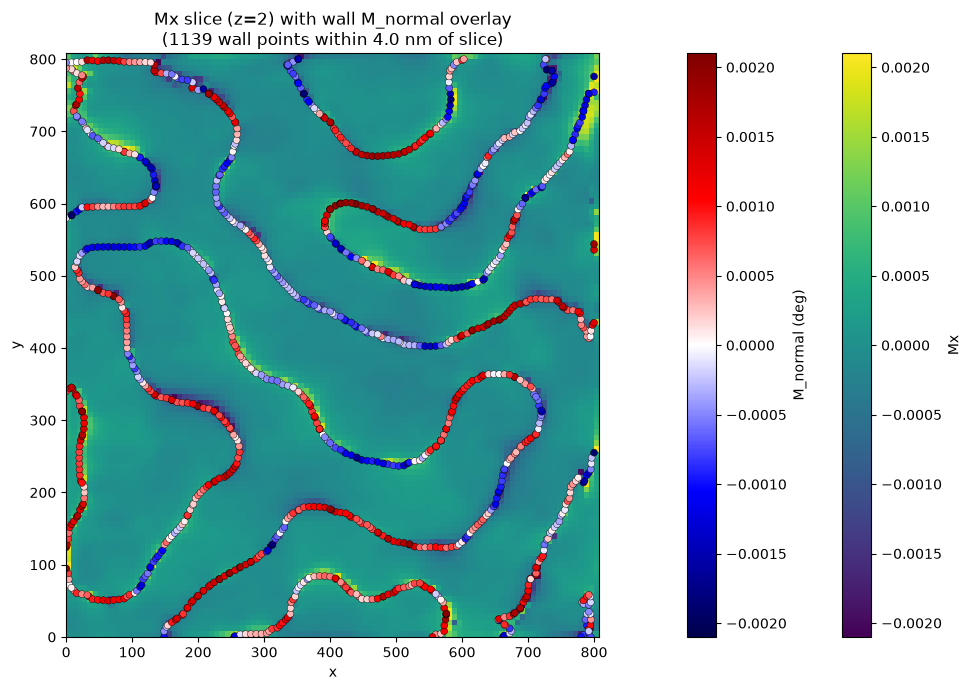

,x,y,z,ix,iy,iz,nx,ny,nz,tx,ty,tz,Mx,My,Mz,M_normal,psi_unsigned,psi_chiral,degenerate,vertex_id
2251,148.389191,0.000000,16.000000,18.548649,0.000000,2.000000,0.991247,-0.006649,0.131855,0.006707,0.999978,-0.0,-0.001006,-0.000159,0.000027,-0.000993,166.976872,-170.522339,False,2251
2252,148.443619,8.000000,16.000000,18.555452,1.000000,2.000000,0.981800,-0.183967,0.047177,0.184172,0.982894,-0.0,-0.000612,-0.000646,0.000191,-0.000473,121.337904,-122.345129,False,2252
2254,254.551880,0.000000,16.000000,31.818985,0.000000,2.000000,-0.695207,0.718338,-0.026023,-0.718582,-0.695443,0.0,0.001603,-0.000699,-0.000496,-0.001604,151.901607,-157.443294,False,2254
2255,256.000000,1.214548,16.000000,32.000000,0.151818,2.000000,-0.439537,0.896571,-0.054485,-0.897904,-0.440191,0.0,0.001454,-0.000699,-0.000508,-0.001238,137.043099,-141.122571,False,2255
2256,264.000000,3.518178,16.000000,33.000000,0.439772,2.000000,-0.111567,0.993756,0.001591,-0.993757,-0.111567,0.0,0.000656,-0.000046,-0.000151,-0.000119,100.177282,-100.442619,False,2256
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4433,784.000000,728.000000,17.022696,98.000000,91.000000,2.127837,-0.872057,0.353080,0.338897,-0.375288,-0.926908,0.0,0.001703,0.001187,-0.000139,-0.001113,122.346435,-122.619516,False,4433
4459,216.000000,752.000000,17.235495,27.000000,94.000000,2.154437,-0.617173,-0.755755,-0.218933,0.774545,-0.632518,0.0,-0.001579,-0.001139,0.000107,0.001812,21.680967,-15.490002,False,4459
4466,792.000000,752.000000,16.451778,99.000000,94.000000,2.056472,-0.622453,0.715000,0.318320,-0.754232,-0.656608,0.0,0.002067,0.000163,-0.000263,-0.001254,126.864256,-126.966243,False,4466
4517,336.000000,792.000000,19.486835,42.000000,99.000000,2.435854,0.813202,-0.507326,-0.285170,0.529305,0.848432,-0.0,-0.001381,-0.001202,0.000551,-0.000670,110.519864,-110.944924,False,4517


In [ ]:
plot_slice_with_wall_overlay(samples[sample_name]['cropped'], wall_df, field='Mx', axis='z', index=None,
                                  angle_col='M_normal', spacing=(8.0, 8.0, 8.0),
                                  tol=4.0, cmap_field='viridis', cmap_angle='seismic')

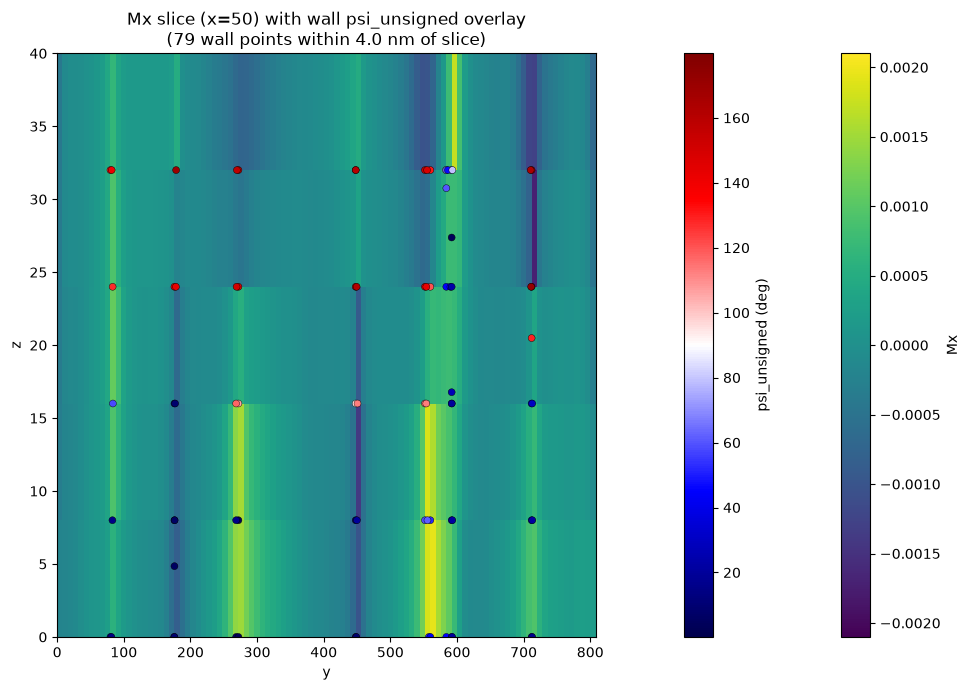

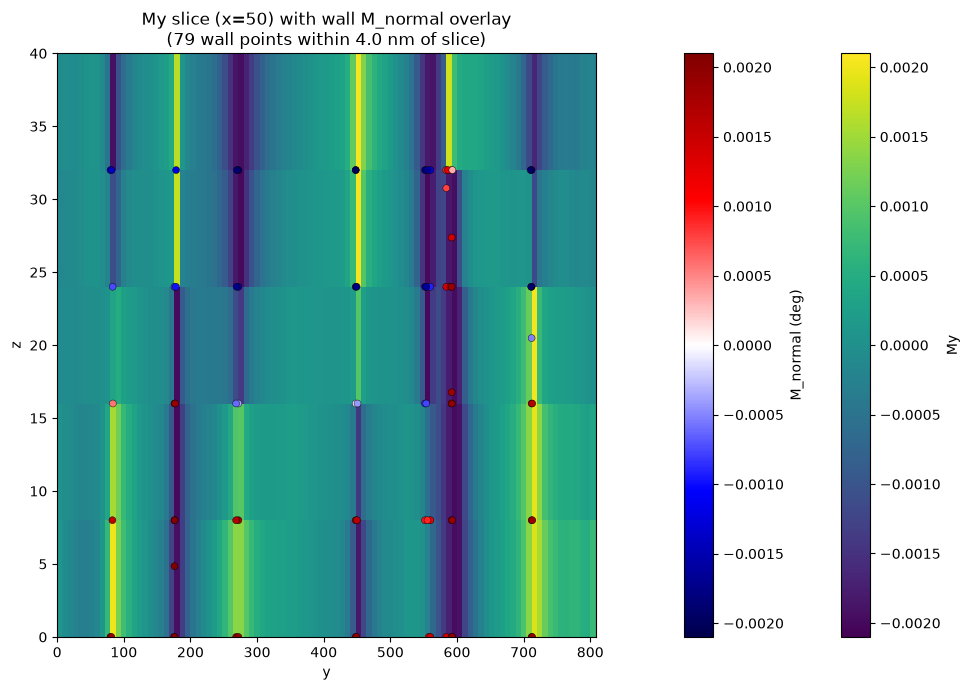

,x,y,z,ix,iy,iz,nx,ny,nz,tx,ty,tz,Mx,My,Mz,M_normal,psi_unsigned,psi_chiral,degenerate,vertex_id
300,402.948944,80.000000,0.000000,50.368618,10.000000,0.000000,0.439225,0.869330,-0.226600,-0.892547,0.450955,0.0,0.000647,0.001930,0.000063,0.001948,16.981049,8.562410,False,300
325,400.000000,81.403366,0.000000,50.000000,10.175421,0.000000,0.336982,0.914388,-0.224361,-0.938309,0.345798,0.0,0.000557,0.001859,0.000020,0.001883,14.004601,3.653698,False,325
326,400.000000,82.942162,8.000000,50.000000,10.367770,1.000000,0.253583,0.958335,-0.131488,-0.966729,0.255804,0.0,0.000811,0.001414,-0.000093,0.001573,15.562946,-15.043968,False,326
550,400.000000,175.554733,0.000000,50.000000,21.944342,0.000000,-0.274702,-0.960795,0.037570,0.961474,-0.274896,0.0,-0.000813,-0.001887,-0.000048,0.002035,8.135459,-7.367253,False,550
551,400.000000,176.000000,4.851561,50.000000,22.000000,0.606445,-0.335649,-0.938488,0.081115,0.941591,-0.336758,0.0,-0.000712,-0.001971,-0.000028,0.002087,5.410549,-0.180377,False,551
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5386,400.000000,592.000000,27.378098,50.000000,74.000000,3.422262,0.774422,-0.608914,0.171740,0.618098,0.786101,-0.0,0.001171,-0.000796,0.000231,0.001431,3.972991,3.926611,False,5386
5387,400.000000,586.417847,32.000000,50.000000,73.302231,4.000000,0.954455,0.116098,-0.274841,-0.120748,0.992683,0.0,0.001065,0.001490,-0.000261,0.001261,47.024005,46.961332,False,5387
5410,400.000000,593.088928,32.000000,50.000000,74.136116,4.000000,0.538283,-0.828797,0.152795,0.838645,0.544679,-0.0,0.001620,0.000735,0.000516,0.000342,79.367705,79.004545,False,5410
5550,398.551819,712.000000,32.000000,49.818977,89.000000,4.000000,0.784458,0.603409,0.143257,-0.609698,0.792634,0.0,-0.001232,-0.001589,0.000013,-0.001924,163.055058,-165.197663,False,5550


In [ ]:
plot_slice_with_wall_overlay(samples[sample_name]['cropped'], wall_df, field='Mx', axis='x', index=None,
                                  angle_col='psi_unsigned', spacing=(8.0, 8.0, 8.0),
                                  tol=4.0, cmap_field='viridis', cmap_angle='seismic')

plot_slice_with_wall_overlay(samples[sample_name]['cropped'], wall_df, field='My', axis='x', index=None,
                                  angle_col='M_normal', spacing=(8.0, 8.0, 8.0),
                                  tol=4.0, cmap_field='viridis', cmap_angle='seismic')

# compare interpolated data

In [ ]:
def compare_interpolation_effect(classified_df, Mx_vol, My_vol, Mz_vol,
                                  method='normal', tol=None):
    """
    Compare Bloch/Neel classification using trilinear-interpolated M
    (the standard pipeline) against nearest-neighbor voxel M (no
    interpolation), to quantify how much interpolation is influencing
    the classification near strict tolerance boundaries.

    Parameters
    ----------
    classified_df : pd.DataFrame
        Output of classify_pure_bloch_neel, must contain ix, iy, iz
        (fractional voxel indices), nx, ny, nz (normal components),
        and 'category' (the interpolation-based classification).
    Mx_vol, My_vol, Mz_vol : ndarray, shape (nz, ny, nx)
        The raw (or smoothed, whichever was used upstream) voxel volumes.
    method, tol : same meaning as in classify_pure_bloch_neel; must match
        whatever was used to produce classified_df['category'], so the
        two classifications are directly comparable.

    Returns
    -------
    df : pd.DataFrame
        classified_df with added columns for the nearest-neighbor M,
        the nearest-neighbor category ('category_nn'), and a boolean
        'agrees' flag.
    """
    df = classified_df.copy()
    nz, ny, nx = Mz_vol.shape

    # Round fractional indices to nearest integer voxel, clip to valid range
    iz_nn = np.clip(df['iz'].round().astype(int), 0, nz - 1)
    iy_nn = np.clip(df['iy'].round().astype(int), 0, ny - 1)
    ix_nn = np.clip(df['ix'].round().astype(int), 0, nx - 1)

    Mx_nn = Mx_vol[iz_nn, iy_nn, ix_nn]
    My_nn = My_vol[iz_nn, iy_nn, ix_nn]
    Mz_nn = Mz_vol[iz_nn, iy_nn, ix_nn]
    M_nn = np.stack([Mx_nn, My_nn, Mz_nn], axis=1)

    n_v = df[['nx', 'ny', 'nz']].values  # reuse existing normals; only M sampling changes
    M_n_nn = np.einsum('ij,ij->i', M_nn, n_v)
    mag_nn = np.linalg.norm(M_nn, axis=1)

    category_nn = np.full(len(df), 'unclassified', dtype=object)

    if method == 'normal':
        tol = 0.0005 if tol is None else tol
        is_bloch = np.abs(M_n_nn) < tol
        is_neel = np.abs(np.abs(M_n_nn) - mag_nn) < tol
        df['M_n_nn'] = M_n_nn

    elif method == 'psi':
        tol = 0.005 if tol is None else tol
        M_t_vec_nn = M_nn - M_n_nn[:, None] * n_v
        M_t_mag_nn = np.linalg.norm(M_t_vec_nn, axis=1)
        psi_rad_nn = np.arctan2(M_t_mag_nn, M_n_nn)
        is_bloch = np.abs(psi_rad_nn - np.pi / 2) < tol
        is_neel = (np.abs(psi_rad_nn - 0.0) < tol) | (np.abs(psi_rad_nn - np.pi) < tol)
        df['psi_rad_nn'] = psi_rad_nn

    else:
        raise ValueError("method must be 'normal' or 'psi'")

    category_nn[is_bloch] = 'bloch'
    category_nn[is_neel] = 'neel'
    df['Mx_nn'], df['My_nn'], df['Mz_nn'] = Mx_nn, My_nn, Mz_nn
    df['category_nn'] = category_nn
    df['agrees'] = df['category'] == df['category_nn']

    # --- Summary ---
    n_total = len(df)
    n_agree = df['agrees'].sum()
    print(f"[{method}] Agreement: {n_agree} / {n_total} "
          f"({100 * n_agree / n_total:.1f}%)")

    confusion = pd.crosstab(df['category'], df['category_nn'],
                             rownames=['interpolated'], colnames=['nearest-neighbor'])
    print("\nConfusion matrix (interpolated vs. nearest-neighbor):")
    print(confusion)

    # Flag cases that specifically flipped between a "pure" label and something else,
    # since these are the ones most likely to be interpolation artifacts.
    flips = df[~df['agrees'] & ((df['category'].isin(['bloch', 'neel'])) |
                                  (df['category_nn'].isin(['bloch', 'neel'])))]
    print(f"\n{len(flips)} vertices flipped in/out of a 'pure' label "
          f"due to interpolation vs. nearest-neighbor sampling.")

    return df

In [ ]:
def plot_interpolation_mismatch(df, spacing=(8.0, 8.0, 8.0)):
    """
    Two-panel plot: (1) mismatch count per z-layer, (2) spatial map of
    mismatched vertices (x-y positions, colored by which category they
    flipped between).
    """
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    mismatch_by_layer = (~df['agrees']).groupby(df['iz'].round().astype(int)).sum()
    total_by_layer = df.groupby(df['iz'].round().astype(int)).size()
    frac_by_layer = mismatch_by_layer / total_by_layer

    axes[0].bar(frac_by_layer.index, frac_by_layer.values, color='tab:orange')
    axes[0].set_xlabel('z voxel layer')
    axes[0].set_ylabel('fraction mismatched')
    axes[0].set_title('Interpolation-driven classification disagreement by layer')

    mismatched = df[~df['agrees']]
    agree_pts = df[df['agrees']]
    axes[1].scatter(agree_pts['x'], agree_pts['y'], color='lightgray', s=5, alpha=0.3, label='agree')
    axes[1].scatter(mismatched['x'], mismatched['y'], color='red', s=15, label='mismatch')
    axes[1].set_xlabel('x (nm)')
    axes[1].set_ylabel('y (nm)')
    axes[1].set_title('Spatial location of mismatched vertices')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

In [ ]:
def plot_interpolation_mismatch(df, spacing=(8.0, 8.0, 8.0)):
    """
    Two-panel plot: (1) mismatch count per z-layer, (2) spatial map of
    mismatched vertices (x-y positions, colored by which category they
    flipped between).
    """
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    mismatch_by_layer = (~df['agrees']).groupby(df['iz'].round().astype(int)).sum()
    total_by_layer = df.groupby(df['iz'].round().astype(int)).size()
    frac_by_layer = mismatch_by_layer / total_by_layer

    axes[0].bar(frac_by_layer.index, frac_by_layer.values, color='tab:orange')
    axes[0].set_xlabel('z voxel layer')
    axes[0].set_ylabel('fraction mismatched')
    axes[0].set_title('Interpolation-driven classification disagreement by layer')

    mismatched = df[~df['agrees']]
    agree_pts = df[df['agrees']]
    axes[1].scatter(agree_pts['x'], agree_pts['y'], color='lightgray', s=5, alpha=0.3, label='agree')
    axes[1].scatter(mismatched['x'], mismatched['y'], color='red', s=15, label='mismatch')
    axes[1].set_xlabel('x (nm)')
    axes[1].set_ylabel('y (nm)')
    axes[1].set_title('Spatial location of mismatched vertices')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

[normal] tol=0.0005: 571 bloch, 4103 neel, 1013 unclassified (of 5687 total)
[normal] Agreement: 4250 / 5687 (74.7%)

Confusion matrix (interpolated vs. nearest-neighbor):
nearest-neighbor  bloch  neel  unclassified
interpolated                               
bloch               474     2            95
neel                170  2791          1142
unclassified         16    12           985

1437 vertices flipped in/out of a 'pure' label due to interpolation vs. nearest-neighbor sampling.


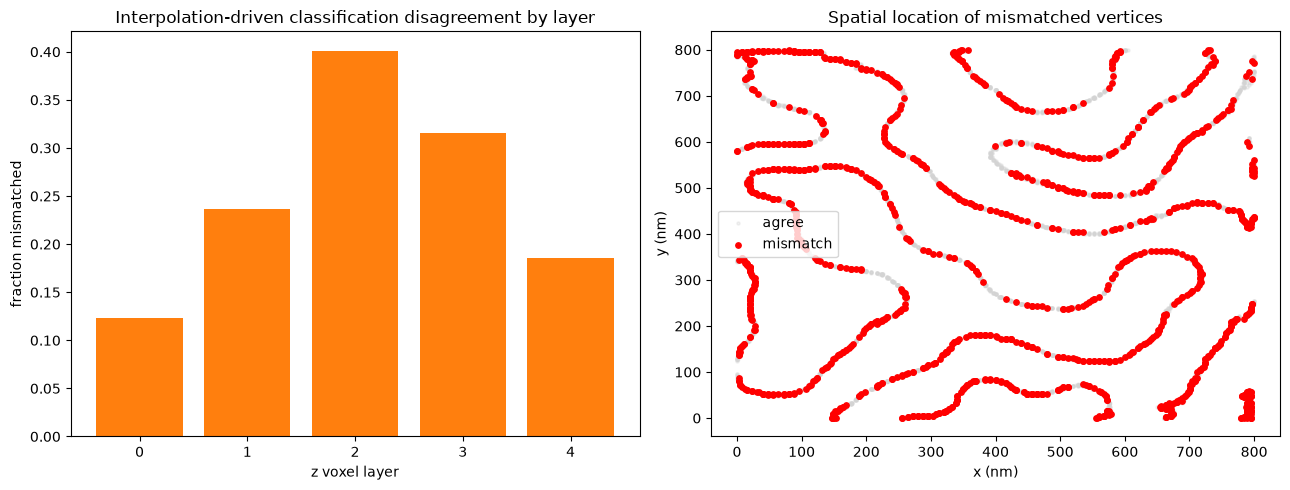

[psi] tol=0.005: 7 bloch, 4 neel, 5676 unclassified (of 5687 total)
[psi] Agreement: 5665 / 5687 (99.6%)

Confusion matrix (interpolated vs. nearest-neighbor):
nearest-neighbor  bloch  unclassified
interpolated                         
bloch                 0             7
neel                  0             4
unclassified         11          5665

22 vertices flipped in/out of a 'pure' label due to interpolation vs. nearest-neighbor sampling.


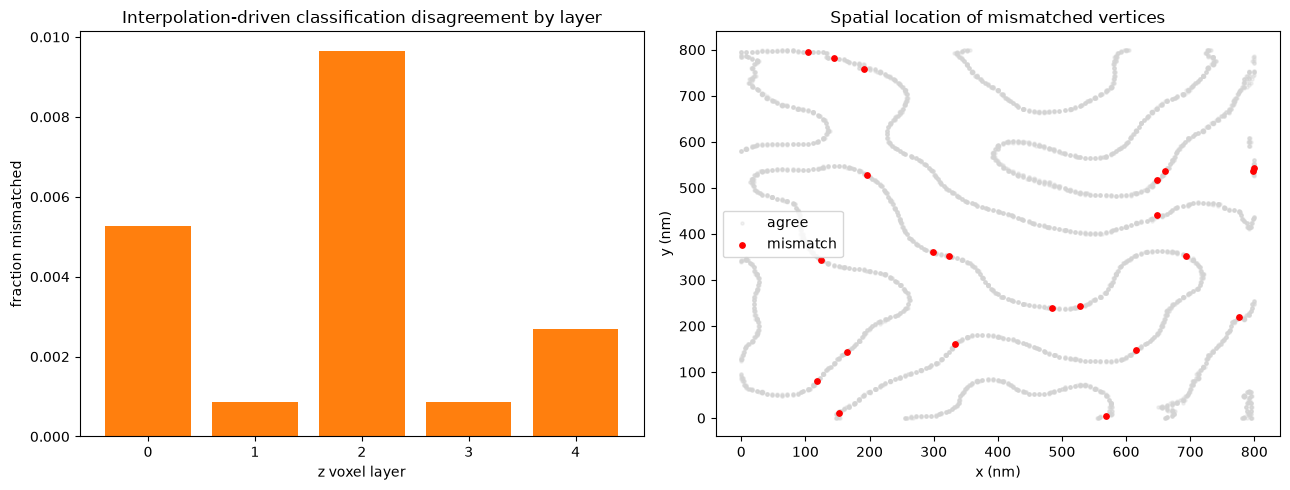

In [ ]:
classified_normal = classify_pure_bloch_neel(wall_df, method='normal', tol=0.0005)
comparison_normal = compare_interpolation_effect(classified_normal, Mx, My, Mz, method='normal', tol=0.0005)
plot_interpolation_mismatch(comparison_normal)

classified_psi = classify_pure_bloch_neel(wall_df, method='psi', tol=0.005)
comparison_psi = compare_interpolation_effect(classified_psi, Mx, My, Mz, method='psi', tol=0.005)
plot_interpolation_mismatch(comparison_psi)

## 6. save the cropped volume to disk
The cropped volume already lives at `samples[name]['cropped']`, so no extra saving is required to keep working in this notebook. If you want a standalone file per sample (e.g. to hand off or re-load later), `.npz` is the simplest option:

In [ ]:
stop

NameError: name 'stop' is not defined

In [ ]:
def save_sample_data(save_dir, sample_name, cropped, wall_df,
                      spacing=(8.0, 8.0, 8.0), z_offset=0, sigma = None, date = None, Delta=None,
                      extra_metadata=None):
    """
    Save the cropped volume and wall-analysis DataFrame for one sample,
    in a format suitable for later cross-sample/material comparison.

    Parameters
    ----------
    save_dir : str
        Directory to save into (created if it doesn't exist).
    sample_name : str
        Identifier for this sample/material, used in filenames and
        stamped into the saved data for later grouping.
    cropped : dict
        The cropped sample dict, expected to contain 'Mx', 'My', 'Mz',
        'magnitude', and 'shape'.
    wall_df : pd.DataFrame
        The per-vertex wall analysis table (normals, psi, chirality, etc.)
    spacing : tuple
        (dz, dy, dx) physical voxel size, in nm.
    z_offset : int
        Offset applied to bring local z-indices back into the original
        volume's index frame (as discussed earlier).
    Delta : float or None
        Domain wall width parameter, if known/relevant, saved as metadata.
    extra_metadata : dict or None
        Any additional key-value info you want stored alongside (e.g.
        material composition, deposition conditions, notes).
    """
    os.makedirs(save_dir, exist_ok=True)

    # --- Save volume arrays ---
    volume_path = os.path.join(save_dir, f'{sample_name}_sigma{sigma}_volume_{date}.npz')
    np.savez_compressed(
        volume_path,
        Mx=cropped['Mx'], My=cropped['My'], Mz=cropped['Mz'],
        magnitude=cropped['magnitude'],
        shape=np.array(cropped['shape']),
        spacing=np.array(spacing),
        z_offset=z_offset,
    )

    # --- Save wall_df, tagged with sample identity ---
    df_out = wall_df.copy()
    df_out['sample_name'] = sample_name
    df_path = os.path.join(save_dir, f'{sample_name}_wall_df_{date}.csv')
    df_out.to_csv(df_path, index=False)

    # --- Save human-readable metadata alongside, for provenance ---
    metadata = {
        'sample_name': sample_name,
        'spacing_nm': list(spacing),
        'z_offset': z_offset,
        'Delta': Delta,
        'n_wall_vertices': len(wall_df),
        'volume_shape': list(cropped['shape']),
    }
    if extra_metadata:
        metadata.update(extra_metadata)
    meta_path = os.path.join(save_dir, f'{sample_name}_metadata.json')
    with open(meta_path, 'w') as f:
        json.dump(metadata, f, indent=2)

    print(f"Saved: {volume_path}\n       {df_path}\n       {meta_path}")
    return volume_path, df_path, meta_path



save_dir = data_dir

save_sample_data(save_dir, sample_name, samples[sample_name]['cropped'], wall_df,
                      spacing=(8.0, 8.0, 8.0), z_offset=0, sigma = sigma_save, date = '14AUG26', Delta=None,
                      extra_metadata=None)

In [ ]:


save_dir = data_dir

save_sample_data(save_dir, sample_name, samples[sample_name]['cropped'], wall_df,
                      spacing=(8.0, 8.0, 8.0), z_offset=0, sigma = sigma_save, date = '14AUG26', Delta=None,
                      extra_metadata=None)

Saved: C:\Users\emmab\Projects\Vector_Tomography\data_dir\452_sigma1.0_volume_14AUG26.npz
       C:\Users\emmab\Projects\Vector_Tomography\data_dir\452_wall_df_14AUG26.csv
       C:\Users\emmab\Projects\Vector_Tomography\data_dir\452_metadata.json


('C:\\Users\\emmab\\Projects\\Vector_Tomography\\data_dir\\452_sigma1.0_volume_14AUG26.npz',
 'C:\\Users\\emmab\\Projects\\Vector_Tomography\\data_dir\\452_wall_df_14AUG26.csv',
 'C:\\Users\\emmab\\Projects\\Vector_Tomography\\data_dir\\452_metadata.json')